# Missing Data Analysis — Part 2B · Comparison
## Mechanisms, methods and a "which method when" guide, from the Part 2A simulation

**Author:** Purbasa Bhaduri · M.Sc. Statistics, St. Xavier's University, Kolkata

---

### What this notebook does
Part 2A produced the raw simulation: 1,000 complete datasets, each deleted under **MCAR, MAR and MNAR** at **10–50%** missingness, analysed by every method. Part 2B reads that file and answers the cross-cutting questions:

| # | Question | Section |
|---|---|---|
| 1 | Is the input complete, clean and the design really paired? | **1** |
| 2 | How does each *mechanism* change a method's results, compared with MCAR on the **same datasets**? | **2** |
| 3 | Which *method* is best, where? RMSE and coverage heatmaps, rank tables | **3** |
| 4 | At what missingness level does each method *break* (coverage < 90%, or material bias)? | **4** |
| 5 | Which methods are robust across mechanisms and which are not (method × mechanism interaction)? | **5** |
| 6 | Are the reported standard errors honest? Is a coverage failure caused by bias or by bad SEs? | **6** |
| 7 | Why do the donor-based methods lose? A diagnostic (slope attenuation) | **7** |
| 8 | Findings, claim checks and the **"which method when"** decision guide | **8** |
| 9 | Report card; export of every figure and table (and a README snippet) | **9** |

### Input
`raw_replicates_v2.csv` from the Stage 2.5 zip (`part2A_stage2_v2_outputs.zip`). The notebook finds it by itself (working folder, a zip next to it, your Drive folder, or it asks you to upload it).

### Three design decisions, stated up front
1. **All four coefficients are treated equally.** Part 1 focused on β₁, but the Stage 2.5 results show MNAR hits the intercept β₀ first, so privileging β₁ would hide the main effect. Every table, figure and ranking below is produced for **β₀, β₁, β₂ and β₃**. Single-number summaries (rankings, breaking points, the decision guide) use the **worst case across the four coefficients**: a method is only as good as its weakest coefficient. β₁ appears in the same place as the others.
2. **Paired comparisons wherever possible.** Every replicate applies all three mechanisms and all methods to the *same* complete dataset (and the deleted sets share random numbers). So differences between mechanisms, or between methods, are computed **replicate by replicate**, which removes the dataset-to-dataset noise and gives much tighter Monte Carlo errors than comparing two separate averages.
3. **Complete Case, Regression Imputation and EM are one method here.** Part 2A proved they give identical estimates, SEs and intervals when only $Y$ is missing, so ranking them separately would just rank one method three times. They appear as **"Complete Case (= Regression = EM)"**. Section 1 re-verifies the identity before merging them.

### Thresholds (fixed before looking at results; editable in 1.1)
| Quantity | Rule | Why |
|---|---|---|
| **Coverage breaks** | 95% interval coverage **< 90%** | the inferential criterion; scale-free, so it treats all four coefficients alike |
| **Bias is material** | $\lvert\text{bias}\rvert \ge 0.5 \times$ SD of the **Full-Data** estimator of that coefficient | scale-free ("standardised bias"), so β₀ (true value 5) and β₃ (true value 1) are judged by the same yardstick; this is the convention of Burton et al. (2006) |
| **SE is honest** | SE ratio (mean SE ÷ empirical SD) in **0.90–1.10** | same band as Part 2A |
| **Paired difference is flagged** | $\lvert z\rvert > 3$ | there are hundreds of comparisons, so the flag is deliberately strict; treat flags as descriptive |
| **A method "ties" the best** | paired $z < 2$ on the difference in squared error vs the best method | respects Monte Carlo error |

*(For reference only, the tables also carry bias as a share of the true coefficient, since Part 2A coloured β₁ by "5% of 2 = 0.10".)*

### Scope of the conclusions
One data-generating model (linear, normal errors, n = 100, three predictors), **only Y is incomplete** (predictors always observed), one specific form for each mechanism (MAR is stronger than Part 1's rule, deletes an exact count), one MNAR strength (slope 1.0), MICE with PMM (k = 5 donors, m = 20). Everything below is a statement about *this* design. The decision guide in Section 8 repeats these limits.

In [1]:
# 1.1  Imports and settings
import os, sys, io, re, json, glob, time, zipfile, shutil, platform, warnings
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm, TwoSlopeNorm, Normalize
from matplotlib.lines import Line2D
try:
    from IPython.display import display, Markdown
except ImportError:
    display, Markdown = print, str
warnings.filterwarnings("ignore")

# ------------------------------ SETTINGS (edit here only) ------------------------------
RAW_NAME          = "raw_replicates_v2.csv"
DRIVE_DIR         = "/content/drive/MyDrive/MissingData_Part2A_Stage2_v2"   # where Stage 2.5 saved its chunks / zip
USE_DRIVE         = True
OUT               = "part2B_outputs"        # everything in here is zipped at the end
COVER_FLOOR       = 0.90                    # coverage below this = the method "breaks"
STD_BIAS_MATERIAL = 0.5                     # |bias| >= this x SD(Full-Data estimator) = material bias
REL_BIAS_REF      = 0.05                    # reference only: |bias| >= 5% of |true beta|
HONEST            = (0.90, 1.10)            # SE ratio band considered honest
Z_FLAG            = 3.0                     # |z| used to flag paired differences
TIE_Z             = 2.0                     # a method "ties" the best if its paired z is below this
N_BOOT            = 1000                    # replicate-bootstrap resamples (breaking-point intervals)
BOOT_SEED         = 20261012
# ---------------------------------------------------------------------------------------

IN_COLAB = "google.colab" in sys.modules
STORE = "local_store"
if USE_DRIVE and IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); STORE = DRIVE_DIR
        print("Google Drive mounted.")
    except Exception as e:
        print("Could not mount Google Drive (", e, "): will look in the working folder only.")
for sub in ["figures", "tables"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#555555",
                     "axes.labelcolor": "#333333", "xtick.color": "#444444", "ytick.color": "#444444"})

# The logbook: every check records PASS / FAIL / SKIP here (summarised in Section 9)
TESTS = []
def record(section, check, passed, detail=""):
    TESTS.append({"section": section, "check": check, "result": "PASS" if passed else "FAIL", "detail": detail})
    print(("PASS  " if passed else "FAIL  ") + f"[{section}] {check}" + (f"  ->  {detail}" if detail else ""))
def record_skip(section, check, why):
    TESTS.append({"section": section, "check": check, "result": "SKIP", "detail": why}); print(f"SKIP  [{section}] {check}  ->  {why}")

# ---- the protocol constants of Parts 1-2A (do not change) ----
TRUE   = {"b0": 5.0, "b1": 2.0, "b2": -1.5, "b3": 1.0}
COEFS  = ["b0", "b1", "b2", "b3"]
CLAB   = {"b0": r"$\beta_0$", "b1": r"$\beta_1$", "b2": r"$\beta_2$", "b3": r"$\beta_3$"}
CNAME  = {"b0": "beta0", "b1": "beta1", "b2": "beta2", "b3": "beta3"}
MECHS  = ["MCAR", "MAR", "MNAR"]
LEVELS = [10, 20, 30, 40, 50]
# method families: the three identical methods are merged into one
FAMS   = ["Complete Case", "Mean Imputation", "Hot-Deck", "Stochastic Regression", "MICE"]
FLAB   = {"Complete Case": "Complete Case\n(= Regression = EM)", "Mean Imputation": "Mean Imputation", "Hot-Deck": "Hot-Deck",
          "Stochastic Regression": "Stochastic\nRegression", "MICE": "MICE (PMM)"}
FLAB1  = {k: v.replace("\n", " ") for k, v in FLAB.items()}
PAL    = {"Complete Case": "#1B3A5C", "Mean Imputation": "#C8553D", "Hot-Deck": "#E3A32B",
          "Stochastic Regression": "#4E8F4B", "MICE": "#8A4F9E", "Full Data": "#6E6E6E"}
MARK   = {"Complete Case": "o", "Mean Imputation": "s", "Hot-Deck": "^", "Stochastic Regression": "D", "MICE": "v"}
CPAL   = {"b0": "#1B3A5C", "b1": "#C8553D", "b2": "#4E8F4B", "b3": "#8A4F9E"}
CMARK  = {"b0": "o", "b1": "s", "b2": "^", "b3": "D"}
MECH_DESC = {"MCAR": "MCAR: every row equally likely to lose Y",
             "MAR": "MAR: low-X1 rows lose Y first (observed variable)",
             "MNAR": "MNAR: high-Y rows lose Y first (hidden value)"}
FIG_BG = "#FCFBF8"
FIGS = []
def savefig(fig, name):
    path = f"{OUT}/figures/{name}.png"
    fig.savefig(path, dpi=200, facecolor=fig.get_facecolor(), bbox_inches="tight"); FIGS.append(path); plt.show(); return path
def save_table(df, name, index=True):
    df.to_csv(f"{OUT}/tables/{name}.csv", index=index); return df
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| run", time.strftime("%Y-%m-%d %H:%M"))

Mounted at /content/drive
Google Drive mounted.
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0 | run 2026-10-12 16:11


---
## Section 1 · Load, validate, and set up the paired structure

### 1.1b Find and load the data
The notebook looks, in this order, for: (1) `raw_replicates_v2.csv` in the working folder (or any sub-folder, e.g. an unzipped Stage 2.5 folder); (2) a `.zip` containing it, in the working folder or in your Drive folder; (3) the 40 checkpoint chunks in `MissingData_Part2A_Stage2_v2/main_chunks`; (4) otherwise it asks you to upload the file (Colab). It also picks up `summary_all_coefficients.csv` if it is in the same zip or folder, to cross-check our recomputation against Part 2A's own summary.

In [2]:
# 1.2  Find and load raw_replicates_v2.csv (and, if available, Part 2A's summary file for a cross-check)
SUMMARY_NAME = "summary_all_coefficients.csv"
def _from_zip(zpath, name):
    with zipfile.ZipFile(zpath) as zf:
        hit = [n for n in zf.namelist() if n.endswith("/" + name) or n == name]
        return pd.read_csv(zf.open(hit[0])) if hit else None
def _find(name, loader_kind):
    # 1 loose file anywhere below the working folder
    for p in [name] + glob.glob(f"**/{name}", recursive=True):
        if os.path.exists(p):
            return pd.read_csv(p), p
    # 2 a zip
    for z in glob.glob("*.zip") + glob.glob("**/*.zip", recursive=True) + glob.glob(f"{STORE}/*.zip"):
        try:
            d = _from_zip(z, name)
        except Exception:
            d = None
        if d is not None:
            return d, f"{name} inside {z}"
    # 3 stage 2.5 chunks (raw only)
    if loader_kind == "raw":
        ch = sorted(glob.glob(f"{STORE}/main_chunks/main_chunk_*.csv"))
        if ch:
            return pd.concat([pd.read_csv(p) for p in ch], ignore_index=True), f"{len(ch)} chunk files in {STORE}/main_chunks"
    return None, None

raw, raw_src = _find(RAW_NAME, "raw")
if raw is None and IN_COLAB:
    from google.colab import files
    print(f"Could not find {RAW_NAME}. Please upload it (or the Stage 2.5 zip) ...")
    for nm, content in files.upload().items():
        open(nm, "wb").write(content)
    raw, raw_src = _find(RAW_NAME, "raw")
if raw is None:
    raise FileNotFoundError(f"{RAW_NAME} not found. Put raw_replicates_v2.csv (or the Stage 2.5 zip) in the working folder and re-run.")
summ2a, summ_src = _find(SUMMARY_NAME, "summary")
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from {raw_src}")
print("Part 2A summary file for cross-check:", summ_src or "not found (that check will be skipped)")

Loaded 106,000 rows x 25 columns from raw_replicates_v2.csv inside drive/MyDrive/MissingData_Part2A_Stage2_v2/part2A_stage2_v2_outputs.zip
Part 2A summary file for cross-check: summary_all_coefficients.csv inside drive/MyDrive/MissingData_Part2A_Stage2/part2A_stage2_outputs.zip


In [3]:
# 1.3  Validation: is the input what the protocol says it is?
need = ["rep", "mechanism", "severity", "n_missing", "method"] + COEFS + [f"{a}_{c}" for a in ("se", "lo", "hi") for c in COEFS]
record("1", "All required columns are present (estimates, SEs and intervals of all four coefficients)", all(c in raw.columns for c in need))
raw = raw.copy()
R = int(raw["rep"].nunique())
ALLM = ["Complete Case", "Mean Imputation", "Hot-Deck", "Regression Imputation", "Stochastic Regression", "MICE", "EM"]
record("1", "Row count = replicates x 106 (1 Full Data row + 3 mechanisms x 5 levels x 7 methods)", len(raw) == R * 106, f"{len(raw):,} rows, {R} replicates")
K = ["rep", "mechanism", "severity", "method"]
record("1", "Every replicate appears exactly once in every condition", raw.duplicated(K).sum() == 0 and raw.groupby(K[1:]).size().eq(R).all()
       and sorted(raw["rep"].unique()) == list(range(R)), f"{raw.groupby(K[1:]).ngroups} conditions x {R}")
vals = raw[need[5:]]
record("1", "No missing values in estimates, SEs or interval limits", bool(vals.notna().all().all()))
record("1", "All four SEs and all interval widths are positive",
       bool((raw[[f'se_{c}' for c in COEFS]] > 0).all().all() and all((raw[f"hi_{c}"] > raw[f"lo_{c}"]).all() for c in COEFS)))
d_ = raw[raw["mechanism"] != "NONE"]
record("1", "n_missing equals the severity level in every row (exact deletion)", bool((raw["n_missing"] == raw["severity"]).all()))
record("1", "Design is as expected (mechanisms MCAR/MAR/MNAR, levels 10-50%, 7 methods + Full Data)",
       sorted(d_["mechanism"].unique()) == sorted(MECHS) and sorted(d_["severity"].unique()) == LEVELS
       and sorted(d_["method"].unique()) == sorted(ALLM) and set(raw["method"].unique()) == set(ALLM) | {"Full Data"})

# the three identical methods really are identical (estimates, SEs and intervals), so merging them is legitimate
cols = COEFS + [f"{a}_{c}" for a in ("se", "lo", "hi") for c in COEFS]
wide = d_[d_["method"].isin(["Complete Case", "Regression Imputation", "EM"])].pivot_table(index=["rep", "mechanism", "severity"], columns="method", values=cols, aggfunc="first")
worst = max(float((wide[(c, "Complete Case")] - wide[(c, m)]).abs().max()) for c in cols for m in ("Regression Imputation", "EM"))
record("1", "Complete Case = Regression Imputation = EM in every estimate, SE and interval (so they are merged below)", worst < 1e-6, f"max difference {worst:.1e}")

# Full Data reference: unbiased and calibrated for every coefficient
fd = raw[raw["method"] == "Full Data"].sort_values("rep")
zb = [abs((fd[c] - TRUE[c]).mean()) / ((fd[c] - TRUE[c]).std(ddof=1) / np.sqrt(len(fd))) for c in COEFS]
record("1", "Full Data: all four coefficients unbiased (|bias| < 4 Monte Carlo SE)", max(zb) < 4, f"largest z = {max(zb):.2f}")
covf = {c: float(((fd[f'lo_{c}'] <= TRUE[c]) & (TRUE[c] <= fd[f'hi_{c}'])).mean()) for c in COEFS}
record("1", "Full Data: 95% coverage within 3.5 Monte Carlo SE for every coefficient",
       all(abs(v - 0.95) <= 3.5 * np.sqrt(0.95 * 0.05 / len(fd)) for v in covf.values()), " / ".join(f"{100 * v:.1f}%" for v in covf.values()))

PASS  [1] All required columns are present (estimates, SEs and intervals of all four coefficients)
PASS  [1] Row count = replicates x 106 (1 Full Data row + 3 mechanisms x 5 levels x 7 methods)  ->  106,000 rows, 1000 replicates
PASS  [1] Every replicate appears exactly once in every condition  ->  106 conditions x 1000
PASS  [1] No missing values in estimates, SEs or interval limits
PASS  [1] All four SEs and all interval widths are positive
PASS  [1] n_missing equals the severity level in every row (exact deletion)
PASS  [1] Design is as expected (mechanisms MCAR/MAR/MNAR, levels 10-50%, 7 methods + Full Data)
PASS  [1] Complete Case = Regression Imputation = EM in every estimate, SE and interval (so they are merged below)  ->  max difference 7.6e-08
PASS  [1] Full Data: all four coefficients unbiased (|bias| < 4 Monte Carlo SE)  ->  largest z = 1.58
PASS  [1] Full Data: 95% coverage within 3.5 Monte Carlo SE for every coefficient  ->  95.7% / 94.1% / 95.3% / 94.7%


### 1.4 The paired structure: one array per quantity
Everything from here on works on arrays indexed **[replicate, mechanism, severity, method]** (1,000 × 3 × 5 × 5), one array for each estimate, SE, and interval limit of each coefficient. Because the *same* replicate index means the *same* complete dataset in every slot, subtracting two slots gives a genuinely paired difference. The Full Data reference is a separate vector of length 1,000, also indexed by replicate.

In [4]:
# 1.4  Build the [replicate, mechanism, severity, method] arrays
core = raw[(raw["mechanism"].isin(MECHS)) & (raw["method"].isin(FAMS))].copy()
core["mi"] = core["mechanism"].map({m: i for i, m in enumerate(MECHS)})
core["fi"] = core["method"].map({f: i for i, f in enumerate(FAMS)})
core = core.sort_values(["rep", "mi", "severity", "fi"]).reset_index(drop=True)
M_, S_, F_ = len(MECHS), len(LEVELS), len(FAMS)
SHAPE = (R, M_, S_, F_)
assert len(core) == R * M_ * S_ * F_
def _chk_order():
    g = core[["rep", "mi", "severity", "fi"]].to_numpy().reshape(SHAPE + (4,))
    return (np.all(g[..., 0] == np.arange(R)[:, None, None, None]) and np.all(g[..., 1] == np.arange(M_)[None, :, None, None])
            and np.all(g[..., 2] == np.array(LEVELS)[None, None, :, None]) and np.all(g[..., 3] == np.arange(F_)[None, None, None, :]))
record("1", "Arrays are laid out [replicate, mechanism, severity, method] with no misalignment", bool(_chk_order()))
EST = {c: core[c].to_numpy(float).reshape(SHAPE) for c in COEFS}
SEA = {c: core[f"se_{c}"].to_numpy(float).reshape(SHAPE) for c in COEFS}
LOA = {c: core[f"lo_{c}"].to_numpy(float).reshape(SHAPE) for c in COEFS}
HIA = {c: core[f"hi_{c}"].to_numpy(float).reshape(SHAPE) for c in COEFS}
ERR = {c: EST[c] - TRUE[c] for c in COEFS}                                        # signed error
COV = {c: ((LOA[c] <= TRUE[c]) & (TRUE[c] <= HIA[c])).astype(float) for c in COEFS}   # 1 = interval contains the truth
WID = {c: HIA[c] - LOA[c] for c in COEFS}
assert np.array_equal(fd["rep"].to_numpy(), np.arange(R))
FERR = {c: fd[c].to_numpy(float) - TRUE[c] for c in COEFS}                        # Full Data signed error, (R,)
FCOV = {c: ((fd[f"lo_{c}"] <= TRUE[c]) & (TRUE[c] <= fd[f"hi_{c}"])).to_numpy(float) for c in COEFS}
SD_FULL = {c: float(FERR[c].std(ddof=1)) for c in COEFS}                          # sampling SD of the Full-Data estimator
print(f"{R} replicates x {M_} mechanisms x {S_} severity levels x {F_} method families = {np.prod(SHAPE):,} cells per coefficient")
print("SD of the Full-Data estimator (the yardstick for 'material bias'):", {c: round(v, 4) for c, v in SD_FULL.items()})

PASS  [1] Arrays are laid out [replicate, mechanism, severity, method] with no misalignment
1000 replicates x 3 mechanisms x 5 severity levels x 5 method families = 75,000 cells per coefficient
SD of the Full-Data estimator (the yardstick for 'material bias'): {'b0': 0.1011, 'b1': 0.1028, 'b2': 0.1035, 'b3': 0.1005}


### 1.5 The performance table (all measures, all four coefficients, with Monte Carlo error)
Same measures as Part 2A (bias, empirical SD, RMSE, mean SE, SE ratio, coverage, width), for every mechanism × severity × method family × coefficient, each with its Monte Carlo SE, plus three additions used later:

* **RMSE ratio**: RMSE divided by the Full-Data RMSE of the same coefficient. 1 means "as good as having no missing data", and it puts β₀…β₃ on one scale.
* **Standardised bias**: $\text{bias} / \text{SD}_\text{Full}$, the scale-free yardstick for "material bias".
* **$z$-scores** $(\hat\beta-\beta)/\widehat{SE}$ per replicate: their **mean** shows bias measured in SE units, their **SD** shows whether the SEs are the right size (Section 6).

In [5]:
# 1.5  Performance table
def jack_ratio(se2, est):
    """Jackknife SE of sqrt(mean(se^2))/sd(est), vectorised over the trailing axes (replicate = axis 0)."""
    n = est.shape[0]; n1 = n - 1
    S, Sx, Sxx = se2.sum(0), est.sum(0), (est ** 2).sum(0)
    m_loo = (S - se2) / n1
    v_loo = ((Sxx - est ** 2) - (Sx - est) ** 2 / n1) / (n1 - 1)
    r = np.sqrt(m_loo / v_loo)
    return np.sqrt(n1 / n * ((r - r.mean(0)) ** 2).sum(0))

def metrics_arrays(c):
    """Every measure for coefficient c as arrays of shape (mechanism, severity, method)."""
    e, se, cv, w = ERR[c], SEA[c], COV[c], WID[c]
    n = e.shape[0]
    bias = e.mean(0); sd = EST[c].std(0, ddof=1); rmse = np.sqrt((e ** 2).mean(0))
    avg_se = np.sqrt((se ** 2).mean(0)); cov = cv.mean(0)
    z = e / se
    return {"bias": bias, "mc_se_bias": sd / np.sqrt(n), "emp_sd": sd, "mc_se_sd": sd / np.sqrt(2 * (n - 1)),
            "rmse": rmse, "mc_se_rmse": (e ** 2).std(0, ddof=1) / np.sqrt(n) / (2 * rmse),
            "rmse_ratio": rmse / np.sqrt((FERR[c] ** 2).mean()),
            "std_bias": bias / SD_FULL[c], "rel_bias": bias / abs(TRUE[c]),
            "avg_se": avg_se, "se_ratio": avg_se / sd, "mc_se_ratio": jack_ratio(se ** 2, EST[c]),
            "coverage": cov, "mc_se_cov": np.sqrt(cov * (1 - cov) / n),
            "width": w.mean(0), "mc_se_width": w.std(0, ddof=1) / np.sqrt(n),
            "mean_z": z.mean(0), "sd_z": z.std(0, ddof=1)}

MA = {c: metrics_arrays(c) for c in COEFS}
rows = []
for c in COEFS:
    for mi, m in enumerate(MECHS):
        for si, s in enumerate(LEVELS):
            for fi, f in enumerate(FAMS):
                r = {"coef": c, "mechanism": m, "severity": s, "method": f, "R": R}
                r.update({k: float(v[mi, si, fi]) for k, v in MA[c].items()})
                rows.append(r)
perf = pd.DataFrame(rows)
save_table(perf, "performance_all_coefficients", index=False)
print(f"Performance table: {len(perf):,} rows (4 coefficients x 3 mechanisms x 5 levels x 5 method families)")

# cross-check against Part 2A's own summary file, when we have it
if summ2a is None:
    record_skip("1", "My performance table equals Part 2A's summary for all four coefficients", "summary_all_coefficients.csv not found; put it next to the data to enable this check")
else:
    s2 = summ2a[summ2a["mechanism"].isin(MECHS) & summ2a["method"].isin(FAMS)]
    mm = perf.merge(s2, on=["coef", "mechanism", "severity", "method"], suffixes=("", "_2a"))
    gap = max(float(np.nanmax(np.abs(mm[k] - mm[k + "_2a"]))) for k in ["bias", "emp_sd", "rmse", "avg_se", "coverage", "width", "se_ratio"])
    record("1", "My performance table equals Part 2A's summary for all four coefficients (bias, SD, RMSE, SE, coverage, width, SE ratio)",
           len(mm) == len(perf) and gap < 1e-8, f"{len(mm)} rows compared; max difference {gap:.1e}")

Performance table: 300 rows (4 coefficients x 3 mechanisms x 5 levels x 5 method families)
PASS  [1] My performance table equals Part 2A's summary for all four coefficients (bias, SD, RMSE, SE, coverage, width, SE ratio)  ->  300 rows compared; max difference 2.4e-15


---
## Section 2 · Mechanism comparison: paired differences versus MCAR

### 2.1 The idea
MCAR is the benign baseline. For each method, coefficient and severity level we ask: **what changes when the same datasets lose their values under MAR or MNAR instead of MCAR?** Because replicate $r$ is the same complete dataset under all three mechanisms, we compute the difference *within each replicate* and average:

$$\Delta_{\text{bias}} = \overline{\left(\hat\beta^{\,\text{mech}}_r-\hat\beta^{\,\text{MCAR}}_r\right)},\qquad \Delta_{\text{cov}} = \overline{\mathbf 1^{\text{mech}}_r-\mathbf 1^{\text{MCAR}}_r},\qquad \Delta_{\text{RMSE}}=\text{RMSE}^{\text{mech}}-\text{RMSE}^{\text{MCAR}}\ (\text{jackknife SE}),$$

where $\mathbf 1_r$ says whether replicate $r$'s interval contained the truth. Each comes with a paired Monte Carlo SE and a $z$ = estimate / SE. **A flag (✱) means $|z| > 3$**, a deliberately strict bar because there are hundreds of such comparisons.

**What to expect:** under MAR (selection on observed $X_1$) Complete Case should barely move. Under MNAR it should move a lot, mostly in the intercept. Whether the *other* methods behave like Complete Case is exactly what this section tests.

In [6]:
# 2.2  Paired differences vs MCAR  (mechanism index 1 = MAR, 2 = MNAR; baseline 0 = MCAR)
def paired_vs_mcar(c):
    out = []
    e, cv, w = ERR[c], COV[c], WID[c]
    for mi in (1, 2):
        d_bias, d_cov, d_wid = e[:, mi] - e[:, 0], cv[:, mi] - cv[:, 0], w[:, mi] - w[:, 0]        # (R, S, F)
        sq_a, sq_b = e[:, mi] ** 2, e[:, 0] ** 2
        n = R
        mse_a, mse_b = sq_a.mean(0), sq_b.mean(0)
        loo_a = np.sqrt((sq_a.sum(0) - sq_a) / (n - 1)); loo_b = np.sqrt((sq_b.sum(0) - sq_b) / (n - 1))   # leave-one-replicate-out RMSEs
        dl = loo_a - loo_b
        d_rmse = np.sqrt(mse_a) - np.sqrt(mse_b)
        se_rmse = np.sqrt((n - 1) / n * ((dl - dl.mean(0)) ** 2).sum(0))
        for si, s in enumerate(LEVELS):
            for fi, f in enumerate(FAMS):
                r = {"coef": c, "mechanism": MECHS[mi], "severity": s, "method": f}
                for nm, arr in (("d_bias", d_bias), ("d_cov", d_cov), ("d_width", d_wid)):
                    x = arr[:, si, fi]; r[nm] = x.mean(); r[nm + "_se"] = x.std(ddof=1) / np.sqrt(n)
                r["d_rmse"], r["d_rmse_se"] = d_rmse[si, fi], se_rmse[si, fi]
                out.append(r)
    return pd.DataFrame(out)
paired = pd.concat([paired_vs_mcar(c) for c in COEFS], ignore_index=True)
for nm in ("d_bias", "d_cov", "d_width", "d_rmse"):
    paired[nm + "_z"] = paired[nm] / paired[nm + "_se"].replace(0, np.nan)
save_table(paired, "paired_differences_vs_MCAR", index=False)

# sanity: Complete Case should be unaffected by MAR (selection depends on X only), at every level and coefficient
cc = paired[(paired["method"] == "Complete Case") & (paired["mechanism"] == "MAR")]
record("2", "Complete Case: MAR vs MCAR makes no detectable difference to bias (|z| < 4 at every level, all four coefficients)",
       bool((cc["d_bias_z"].abs() < 4).all()), f"largest |z| = {cc['d_bias_z'].abs().max():.2f}")
print(f"Paired-difference table: {len(paired):,} rows (4 coefficients x 2 mechanisms x 5 levels x 5 methods)")

PASS  [2] Complete Case: MAR vs MCAR makes no detectable difference to bias (|z| < 4 at every level, all four coefficients)  ->  largest |z| = 2.42
Paired-difference table: 200 rows (4 coefficients x 2 mechanisms x 5 levels x 5 methods)


### 2.3 The tables: what changes at 30% and 50% missingness
Read each cell as **difference vs MCAR (paired MC SE)**, with ✱ when $|z|>3$. Coverage differences are in **percentage points**. The full set (all levels, all measures) is saved as `paired_differences_vs_MCAR.csv`.

In [7]:
# 2.3  Compact tables at 30% and 50%
def star(z): return "✱" if (z is not None and np.isfinite(z) and abs(z) > Z_FLAG) else ""
def paired_table(measure, scale, dec, levels=(30, 50)):
    t = paired[paired["severity"].isin(levels)].copy()
    t["cell"] = [f"{v * scale:+.{dec}f} ({s * scale:.{dec}f}){star(z)}" for v, s, z in zip(t[measure], t[measure + "_se"], t[measure + "_z"])]
    t["col"] = t["mechanism"] + " @" + t["severity"].astype(str) + "%"
    p = t.pivot_table(index=["coef", "method"], columns="col", values="cell", aggfunc="first")
    p = p[[f"{m} @{s}%" for m in ("MAR", "MNAR") for s in levels]]
    p = p.reindex(pd.MultiIndex.from_product([COEFS, FAMS], names=["coef", "method"]))
    p.index = pd.MultiIndex.from_tuples([(CNAME[a], FLAB1[b]) for a, b in p.index], names=["coef", "method"])
    return p
for meas, ttl, scl, dec in (("d_bias", "Change in BIAS vs MCAR", 1, 3), ("d_cov", "Change in COVERAGE vs MCAR (percentage points)", 100, 1)):
    tab = paired_table(meas, scl, dec)
    save_table(tab, f"paired_table_{meas}_30_50")
    display(Markdown(f"#### {ttl}"))
    display(tab)

#### Change in BIAS vs MCAR

col                                             MAR @30%         MAR @50%  \
coef  method                                                                
beta0 Complete Case (= Regression = EM)   -0.001 (0.002)   -0.007 (0.004)   
      Mean Imputation                    +0.596 (0.006)✱  +1.037 (0.009)✱   
      Hot-Deck                           +0.132 (0.004)✱  +0.302 (0.006)✱   
      Stochastic Regression               +0.001 (0.003)   -0.010 (0.005)   
      MICE (PMM)                         +0.070 (0.003)✱  +0.175 (0.005)✱   
beta1 Complete Case (= Regression = EM)   -0.001 (0.003)   +0.012 (0.005)   
      Mean Imputation                    -0.300 (0.006)✱  -0.313 (0.007)✱   
      Hot-Deck                           -0.146 (0.006)✱  -0.267 (0.008)✱   
      Stochastic Regression               +0.002 (0.004)   +0.010 (0.006)   
      MICE (PMM)                         -0.082 (0.004)✱  -0.148 (0.006)✱   
beta2 Complete Case (= Regression = EM)   -0.002 (0.002)   +0.001 (0.003)   
      Mean Imputation                     -0.001 (0.005)   +0.000 (0.006)   
      Hot-Deck                            +0.005 (0.004)  +0.022 (0.006)✱   
      Stochastic Regression               +0.003 (0.003)   -0.002 (0.005)   
      MICE (PMM)                         +0.035 (0.003)✱  +0.090 (0.005)✱   
beta3 Complete Case (= Regression = EM)   +0.001 (0.002)   +0.001 (0.003)   
      Mean Imputation                     -0.009 (0.005)   -0.006 (0.005)   
      Hot-Deck                            -0.010 (0.004)  -0.025 (0.006)✱   
      Stochastic Regression               +0.001 (0.003)   -0.001 (0.005)   
      MICE (PMM)                         -0.026 (0.003)✱  -0.059 (0.004)✱   

col                                            MNAR @30%        MNAR @50%  
coef  method                                                               
beta0 Complete Case (= Regression = EM)  -0.124 (0.002)✱  -0.251 (0.004)✱  
      Mean Imputation                    -0.845 (0.006)✱  -1.493 (0.009)✱  
      Hot-Deck                           -0.285 (0.004)✱  -0.606 (0.007)✱  
      Stochastic Regression              -0.121 (0.003)✱  -0.252 (0.005)✱  
      MICE (PMM)                         -0.233 (0.003)✱  -0.522 (0.006)✱  
beta1 Complete Case (= Regression = EM)  -0.064 (0.003)✱  -0.105 (0.004)✱  
      Mean Imputation                    -0.295 (0.006)✱  -0.310 (0.007)✱  
      Hot-Deck                           -0.181 (0.005)✱  -0.329 (0.007)✱  
      Stochastic Regression              -0.064 (0.004)✱  -0.103 (0.005)✱  
      MICE (PMM)                         -0.183 (0.004)✱  -0.343 (0.006)✱  
beta2 Complete Case (= Regression = EM)  +0.044 (0.002)✱  +0.079 (0.004)✱  
      Mean Imputation                    +0.218 (0.006)✱  +0.234 (0.006)✱  
      Hot-Deck                           +0.132 (0.004)✱  +0.239 (0.007)✱  
      Stochastic Regression              +0.047 (0.003)✱  +0.077 (0.005)✱  
      MICE (PMM)                         +0.132 (0.003)✱  +0.261 (0.005)✱  
beta3 Complete Case (= Regression = EM)  -0.030 (0.002)✱  -0.052 (0.004)✱  
      Mean Imputation                    -0.153 (0.006)✱  -0.168 (0.006)✱  
      Hot-Deck                           -0.085 (0.004)✱  -0.168 (0.007)✱  
      Stochastic Regression              -0.029 (0.003)✱  -0.055 (0.005)✱  
      MICE (PMM)                         -0.090 (0.003)✱  -0.175 (0.005)✱

#### Change in COVERAGE vs MCAR (percentage points)

col                                          MAR @30%      MAR @50%  \
coef  method                                                          
beta0 Complete Case (= Regression = EM)    +1.0 (0.8)    -1.0 (0.9)   
      Mean Imputation                    -72.2 (1.5)✱  -85.9 (1.2)✱   
      Hot-Deck                           -13.8 (1.3)✱  -37.1 (1.7)✱   
      Stochastic Regression                +0.7 (0.6)    -1.0 (0.8)   
      MICE (PMM)                          -4.5 (1.1)✱  -17.6 (1.4)✱   
beta1 Complete Case (= Regression = EM)    +0.0 (0.9)    +0.9 (1.1)   
      Mean Imputation                     -6.2 (0.8)✱    +0.0 (0.0)   
      Hot-Deck                           -24.0 (1.5)✱  -43.6 (1.8)✱   
      Stochastic Regression                -0.2 (0.8)    +0.8 (0.9)   
      MICE (PMM)                         -10.0 (1.3)✱  -23.5 (1.7)✱   
beta2 Complete Case (= Regression = EM)    +0.6 (0.8)    -0.9 (0.9)   
      Mean Imputation                      +3.4 (1.4)    +0.5 (0.4)   
      Hot-Deck                             +1.2 (1.0)   -4.2 (1.4)✱   
      Stochastic Regression                +0.4 (0.7)    -1.6 (0.8)   
      MICE (PMM)                          -3.9 (0.9)✱  -12.5 (1.4)✱   
beta3 Complete Case (= Regression = EM)    +0.6 (0.8)    +1.1 (0.9)   
      Mean Imputation                      +1.8 (1.7)    -0.6 (1.3)   
      Hot-Deck                             -0.3 (0.9)    -2.1 (1.2)   
      Stochastic Regression                +0.4 (0.7)    +1.0 (0.8)   
      MICE (PMM)                           -0.5 (0.8)   -4.9 (1.1)✱   

col                                         MNAR @30%     MNAR @50%  
coef  method                                                         
beta0 Complete Case (= Regression = EM)  -13.0 (1.3)✱  -28.2 (1.6)✱  
      Mean Imputation                    -93.2 (0.8)✱  -94.6 (0.7)✱  
      Hot-Deck                           -49.1 (1.7)✱  -87.2 (1.2)✱  
      Stochastic Regression              -10.7 (1.2)✱  -25.4 (1.5)✱  
      MICE (PMM)                         -37.2 (1.7)✱  -82.0 (1.4)✱  
beta1 Complete Case (= Regression = EM)    -2.9 (1.1)   -5.0 (1.3)✱  
      Mean Imputation                     -6.4 (0.8)✱    +0.0 (0.0)  
      Hot-Deck                           -38.8 (1.6)✱  -59.0 (1.6)✱  
      Stochastic Regression                -2.1 (0.9)   -4.1 (1.2)✱  
      MICE (PMM)                         -35.8 (1.7)✱  -66.4 (1.6)✱  
beta2 Complete Case (= Regression = EM)    -2.5 (0.9)   -4.2 (1.1)✱  
      Mean Imputation                    -16.3 (1.2)✱    -0.4 (0.2)  
      Hot-Deck                           -23.8 (1.5)✱  -45.8 (1.7)✱  
      Stochastic Regression                -1.4 (0.9)   -3.2 (0.9)✱  
      MICE (PMM)                         -23.5 (1.4)✱  -53.8 (1.6)✱  
beta3 Complete Case (= Regression = EM)    +0.9 (0.9)    -0.4 (1.0)  
      Mean Imputation                    -31.6 (1.7)✱  -12.4 (1.1)✱  
      Hot-Deck                           -10.8 (1.2)✱  -26.1 (1.6)✱  
      Stochastic Regression                +0.7 (0.7)    -0.5 (0.9)  
      MICE (PMM)                          -8.3 (1.1)✱  -29.3 (1.6)✱

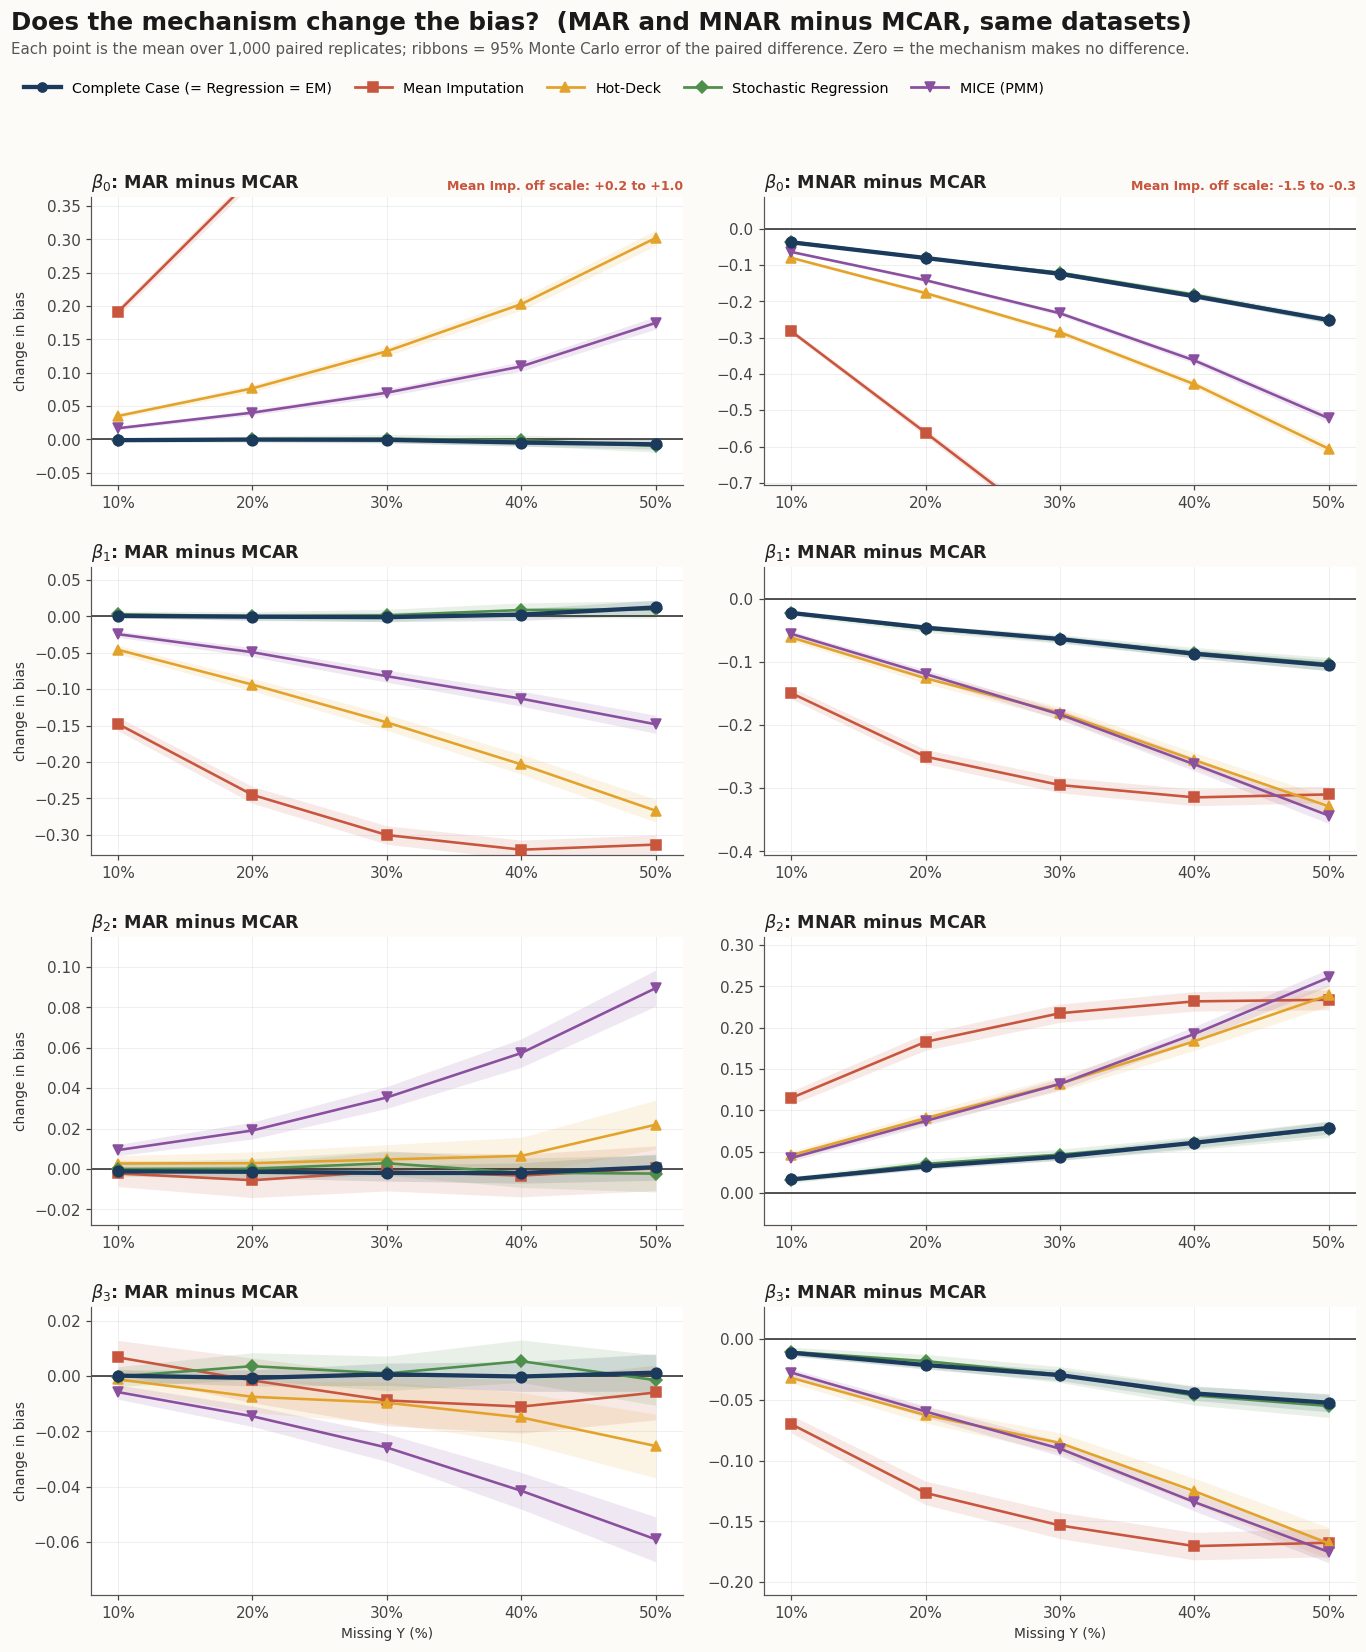

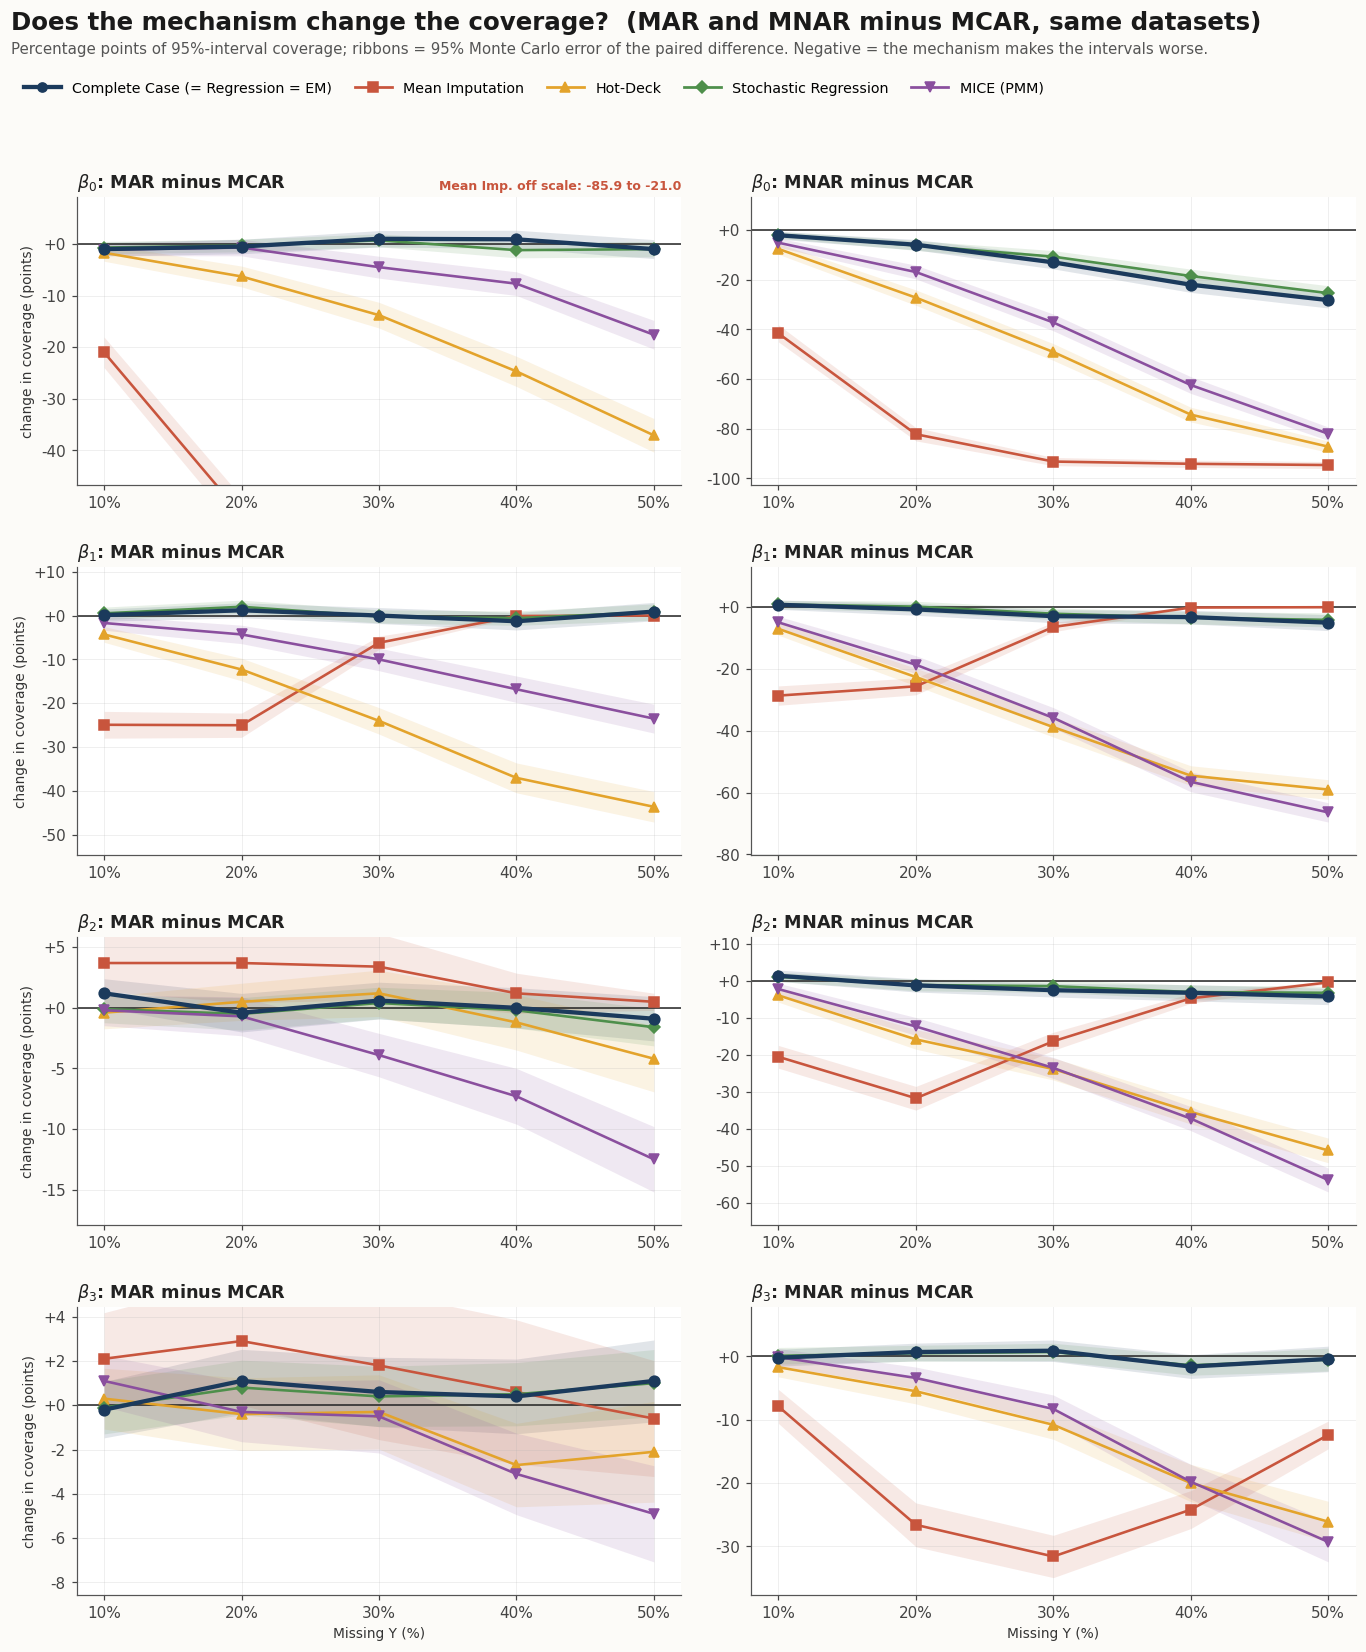

'part2B_outputs/figures/fig11_paired_change_in_coverage.png'

In [8]:
# 2.4  Figures: paired change vs MCAR, all four coefficients (rows) x MAR / MNAR (columns)
def style_ax(ax, title=None, hint=None, ylabel=None, xlabel=True):
    if title: ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color="#222222", pad=15 if hint else 6)
    if hint: ax.text(0, 1.015, hint, transform=ax.transAxes, fontsize=8.3, color="#777777", style="italic", va="bottom")
    ax.set_xticks(LEVELS); ax.set_xticklabels([f"{s}%" for s in LEVELS])
    if xlabel: ax.set_xlabel("Missing Y (%)", fontsize=9)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9)
    ax.set_facecolor("white")

def legend_methods(fig, y=0.93, ncol=5):
    h = [Line2D([0], [0], color=PAL[f], lw=2.8 if f == "Complete Case" else 1.8, marker=MARK[f], ms=6, label=FLAB1[f]) for f in FAMS]
    fig.legend(handles=h, loc="upper left", bbox_to_anchor=(0.01, y), ncol=ncol, frameon=False, fontsize=9.3, handlelength=2.6, columnspacing=1.6)

def delta_figure(measure, title, subtitle, name, scale=1.0, pct=False, ylabel_txt="change vs MCAR"):
    fig, axes = plt.subplots(4, 2, figsize=(12.5, 15), facecolor=FIG_BG)
    for r_, c in enumerate(COEFS):
        for k, mech in enumerate(("MAR", "MNAR")):
            ax = axes[r_, k]
            sub = paired[(paired["coef"] == c) & (paired["mechanism"] == mech)]
            for f in FAMS:
                s_ = sub[sub["method"] == f].sort_values("severity")
                y, e = s_[measure].to_numpy() * scale, s_[measure + "_se"].to_numpy() * scale
                main = f == "Complete Case"
                ax.plot(s_["severity"], y, color=PAL[f], marker=MARK[f], ms=7 if main else 6, lw=2.8 if main else 1.7, zorder=4 if main else 3)
                ax.fill_between(s_["severity"], y - 1.96 * e, y + 1.96 * e, color=PAL[f], alpha=0.13, lw=0, zorder=1)
            ax.axhline(0, color="#222", lw=1)
            # Mean Imputation can dwarf everything: scale to the other methods and say so
            others = sub[sub["method"] != "Mean Imputation"]
            lo = float(np.min(others[measure] * scale - 1.96 * others[measure + "_se"] * scale)); hi = float(np.max(others[measure] * scale + 1.96 * others[measure + "_se"] * scale))
            pad = 0.15 * ((hi - lo) or 1.0); lo, hi = min(lo, 0) - pad, max(hi, 0) + pad
            ax.set_ylim(lo, hi)
            mi = sub[sub["method"] == "Mean Imputation"][measure].to_numpy() * scale
            if (mi < lo).any() or (mi > hi).any():
                ax.text(1.0, 1.015, f"Mean Imp. off scale: {mi.min():+.1f} to {mi.max():+.1f}", transform=ax.transAxes, ha="right", va="bottom",
                        fontsize=8.2, color=PAL["Mean Imputation"], fontweight="bold")
            if pct: ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%+.0f"))
            style_ax(ax, f"{CLAB[c]}: {mech} minus MCAR", None, ylabel_txt if k == 0 else None, xlabel=(r_ == 3))
    fig.suptitle(title, x=0.01, y=0.998, ha="left", fontsize=16, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.972, subtitle, fontsize=9.8, color="#555555", ha="left")
    legend_methods(fig, y=0.963)
    fig.tight_layout(rect=[0, 0, 1, 0.935], h_pad=2.0, w_pad=1.6)
    return savefig(fig, name)

delta_figure("d_bias", "Does the mechanism change the bias?  (MAR and MNAR minus MCAR, same datasets)",
             f"Each point is the mean over {R:,} paired replicates; ribbons = 95% Monte Carlo error of the paired difference. Zero = the mechanism makes no difference.",
             "fig10_paired_change_in_bias", ylabel_txt="change in bias")
delta_figure("d_cov", "Does the mechanism change the coverage?  (MAR and MNAR minus MCAR, same datasets)",
             f"Percentage points of 95%-interval coverage; ribbons = 95% Monte Carlo error of the paired difference. Negative = the mechanism makes the intervals worse.",
             "fig11_paired_change_in_coverage", scale=100.0, pct=True, ylabel_txt="change in coverage (points)")

---
## Section 3 · Method ranking: RMSE and coverage heatmaps, rank tables

### 3.1 How we compare methods
Two complementary criteria, because they fail differently:

* **RMSE ratio** (accuracy): RMSE ÷ the Full-Data RMSE of the same coefficient. 1.00 = as accurate as having no missing data; 2.00 = the typical error is twice as large. It combines bias and variability and is comparable across β₀…β₃.
* **Coverage** (honest inference): how often the 95% interval contains the truth.

A method can have a small RMSE and still fail on coverage (if its SEs are too small) or the reverse. The heatmaps show every coefficient (rows) under every mechanism (columns); the rank tables then reduce them to "who wins, and who is statistically tied with the winner".

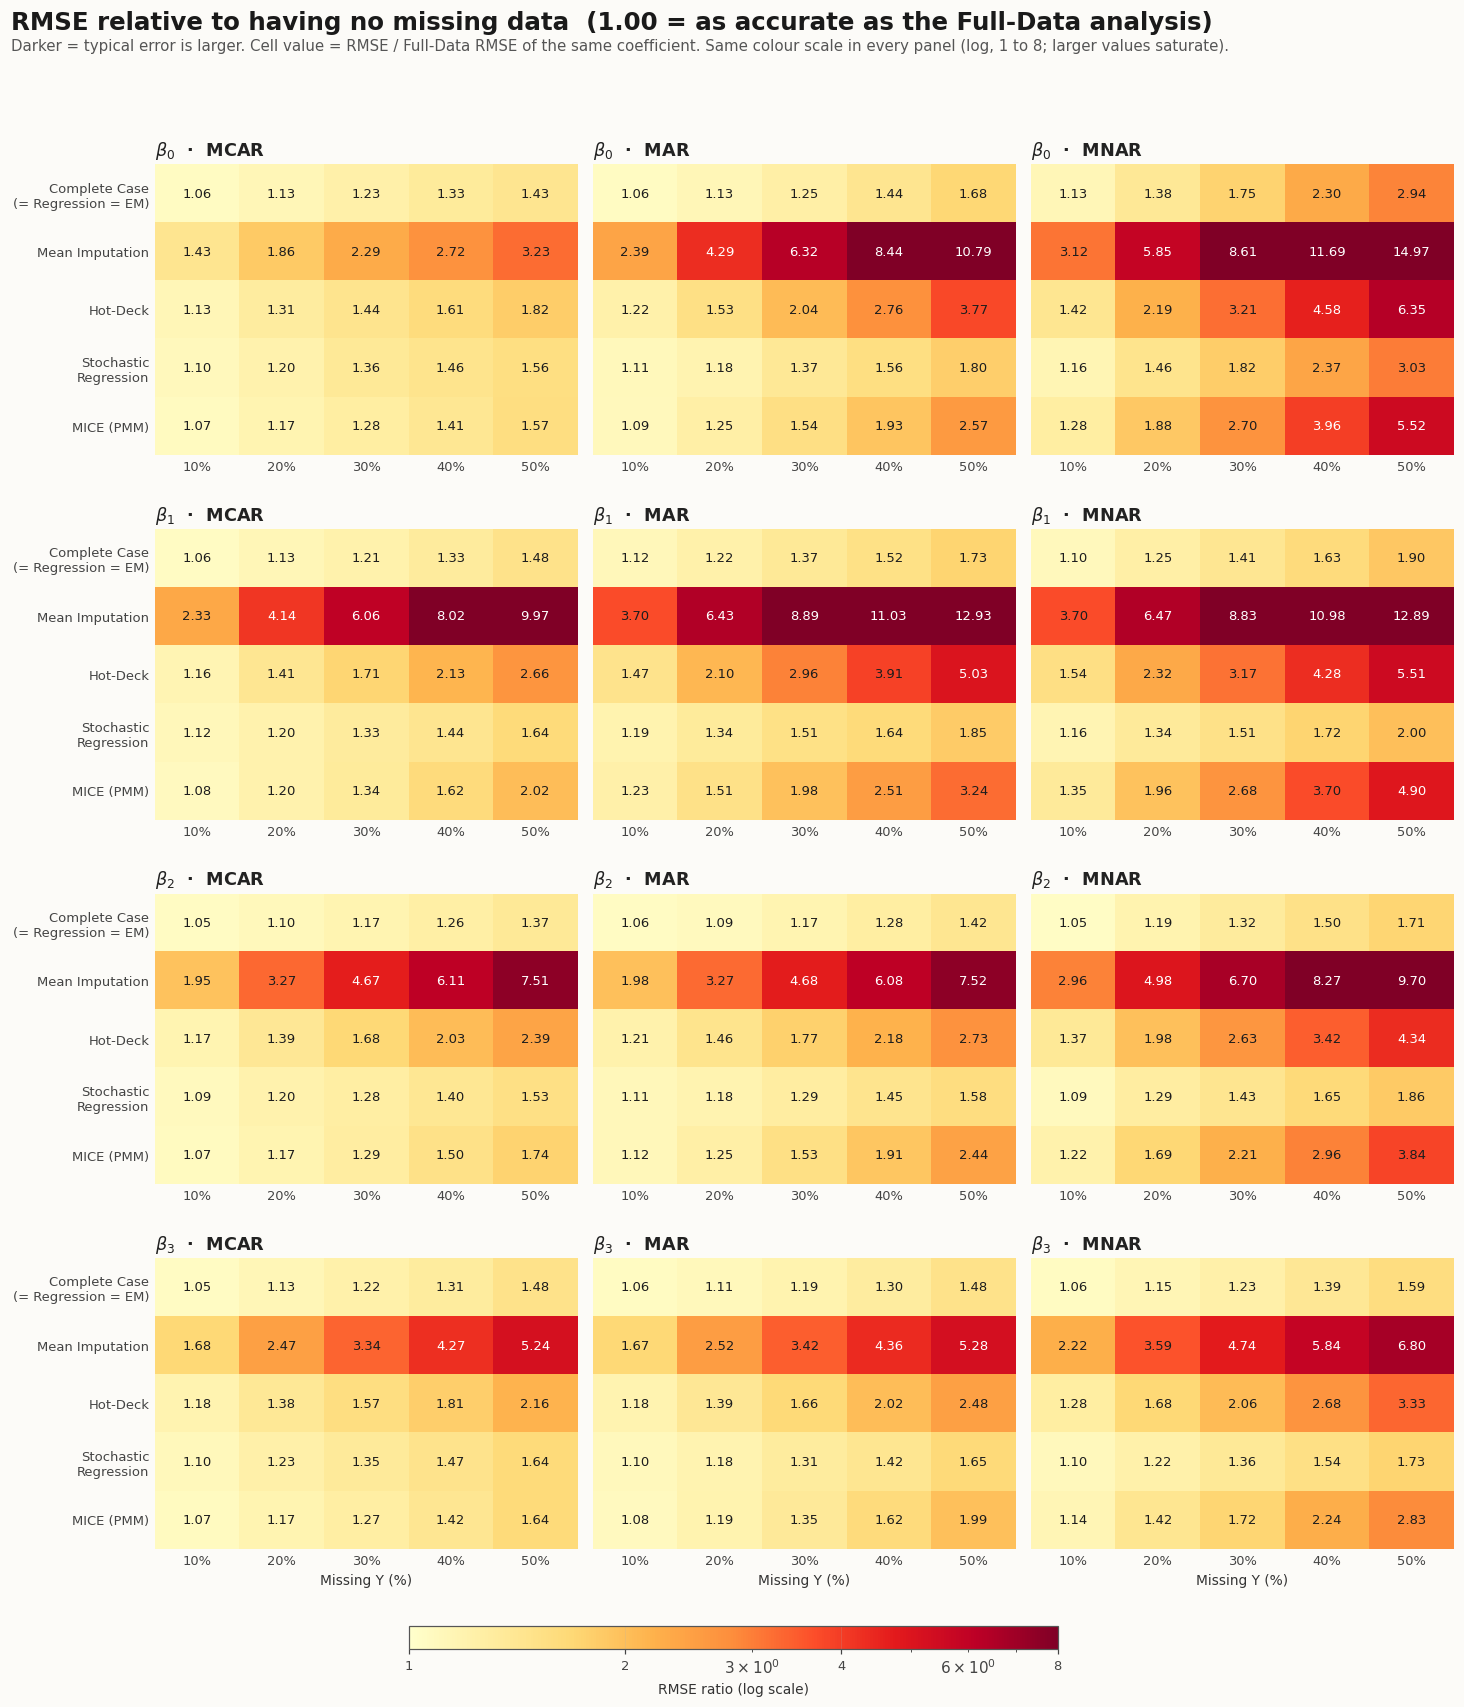

'part2B_outputs/figures/fig12_rmse_ratio_heatmaps.png'

In [9]:
# 3.2  Heatmap machinery + RMSE-ratio heatmaps (4 coefficients x 3 mechanisms)
def mat(c, mi, key):
    return MA[c][key][mi]                       # (severity, method) -> we want rows = method, cols = severity
def draw_heat(ax, M, fmt, cmap, norm, rowlabels=None, show_rows=True, fs=8.6, textfn=None):
    ax.imshow(M, cmap=cmap, norm=norm, aspect="auto")
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            rgba = plt.get_cmap(cmap)(norm(v)) if np.isfinite(v) else (1, 1, 1, 1)
            lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            ax.text(j, i, textfn(v) if textfn else fmt.format(v), ha="center", va="center", fontsize=fs, color="white" if lum < 0.45 else "#1d1d1d")
    ax.set_xticks(range(len(LEVELS))); ax.set_xticklabels([f"{s}%" for s in LEVELS], fontsize=8.5)
    ax.set_yticks(range(len(FAMS)))
    ax.set_yticklabels([FLAB[f] for f in FAMS] if show_rows else [], fontsize=8.6)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(length=0)

def heat_grid(key, title, subtitle, cmap, norm, fmt, name, textfn=None, cbar_label="", cbar_fmt=None, ticks=None):
    fig, axes = plt.subplots(4, 3, figsize=(13.4, 15.2), facecolor=FIG_BG)
    for r_, c in enumerate(COEFS):
        for mi, mech in enumerate(MECHS):
            ax = axes[r_, mi]
            M = MA[c][key][mi].T                # rows = method families, cols = severity
            draw_heat(ax, M, fmt, cmap, norm, show_rows=(mi == 0), textfn=textfn)
            ax.set_title(f"{CLAB[c]}  ·  {mech}", loc="left", fontsize=11.5, fontweight="bold", color="#222222", pad=6)
            if r_ == 3: ax.set_xlabel("Missing Y (%)", fontsize=9)
    fig.suptitle(title, x=0.01, y=0.998, ha="left", fontsize=16, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.974, subtitle, fontsize=9.8, color="#555555", ha="left")
    fig.tight_layout(rect=[0, 0.045, 1, 0.955], h_pad=2.0, w_pad=1.0)
    cax = fig.add_axes([0.28, 0.018, 0.44, 0.014])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal", ticks=ticks)
    cb.set_label(cbar_label, fontsize=9); cb.ax.tick_params(labelsize=8.5)
    if cbar_fmt: cb.ax.xaxis.set_major_formatter(cbar_fmt)
    return savefig(fig, name)

heat_grid("rmse_ratio", "RMSE relative to having no missing data  (1.00 = as accurate as the Full-Data analysis)",
          "Darker = typical error is larger. Cell value = RMSE / Full-Data RMSE of the same coefficient. Same colour scale in every panel (log, 1 to 8; larger values saturate).",
          "YlOrRd", LogNorm(vmin=1.0, vmax=8.0), "{:.2f}", "fig12_rmse_ratio_heatmaps", cbar_label="RMSE ratio (log scale)",
          ticks=[1, 2, 4, 8], cbar_fmt=mtick.FormatStrFormatter("%g"))

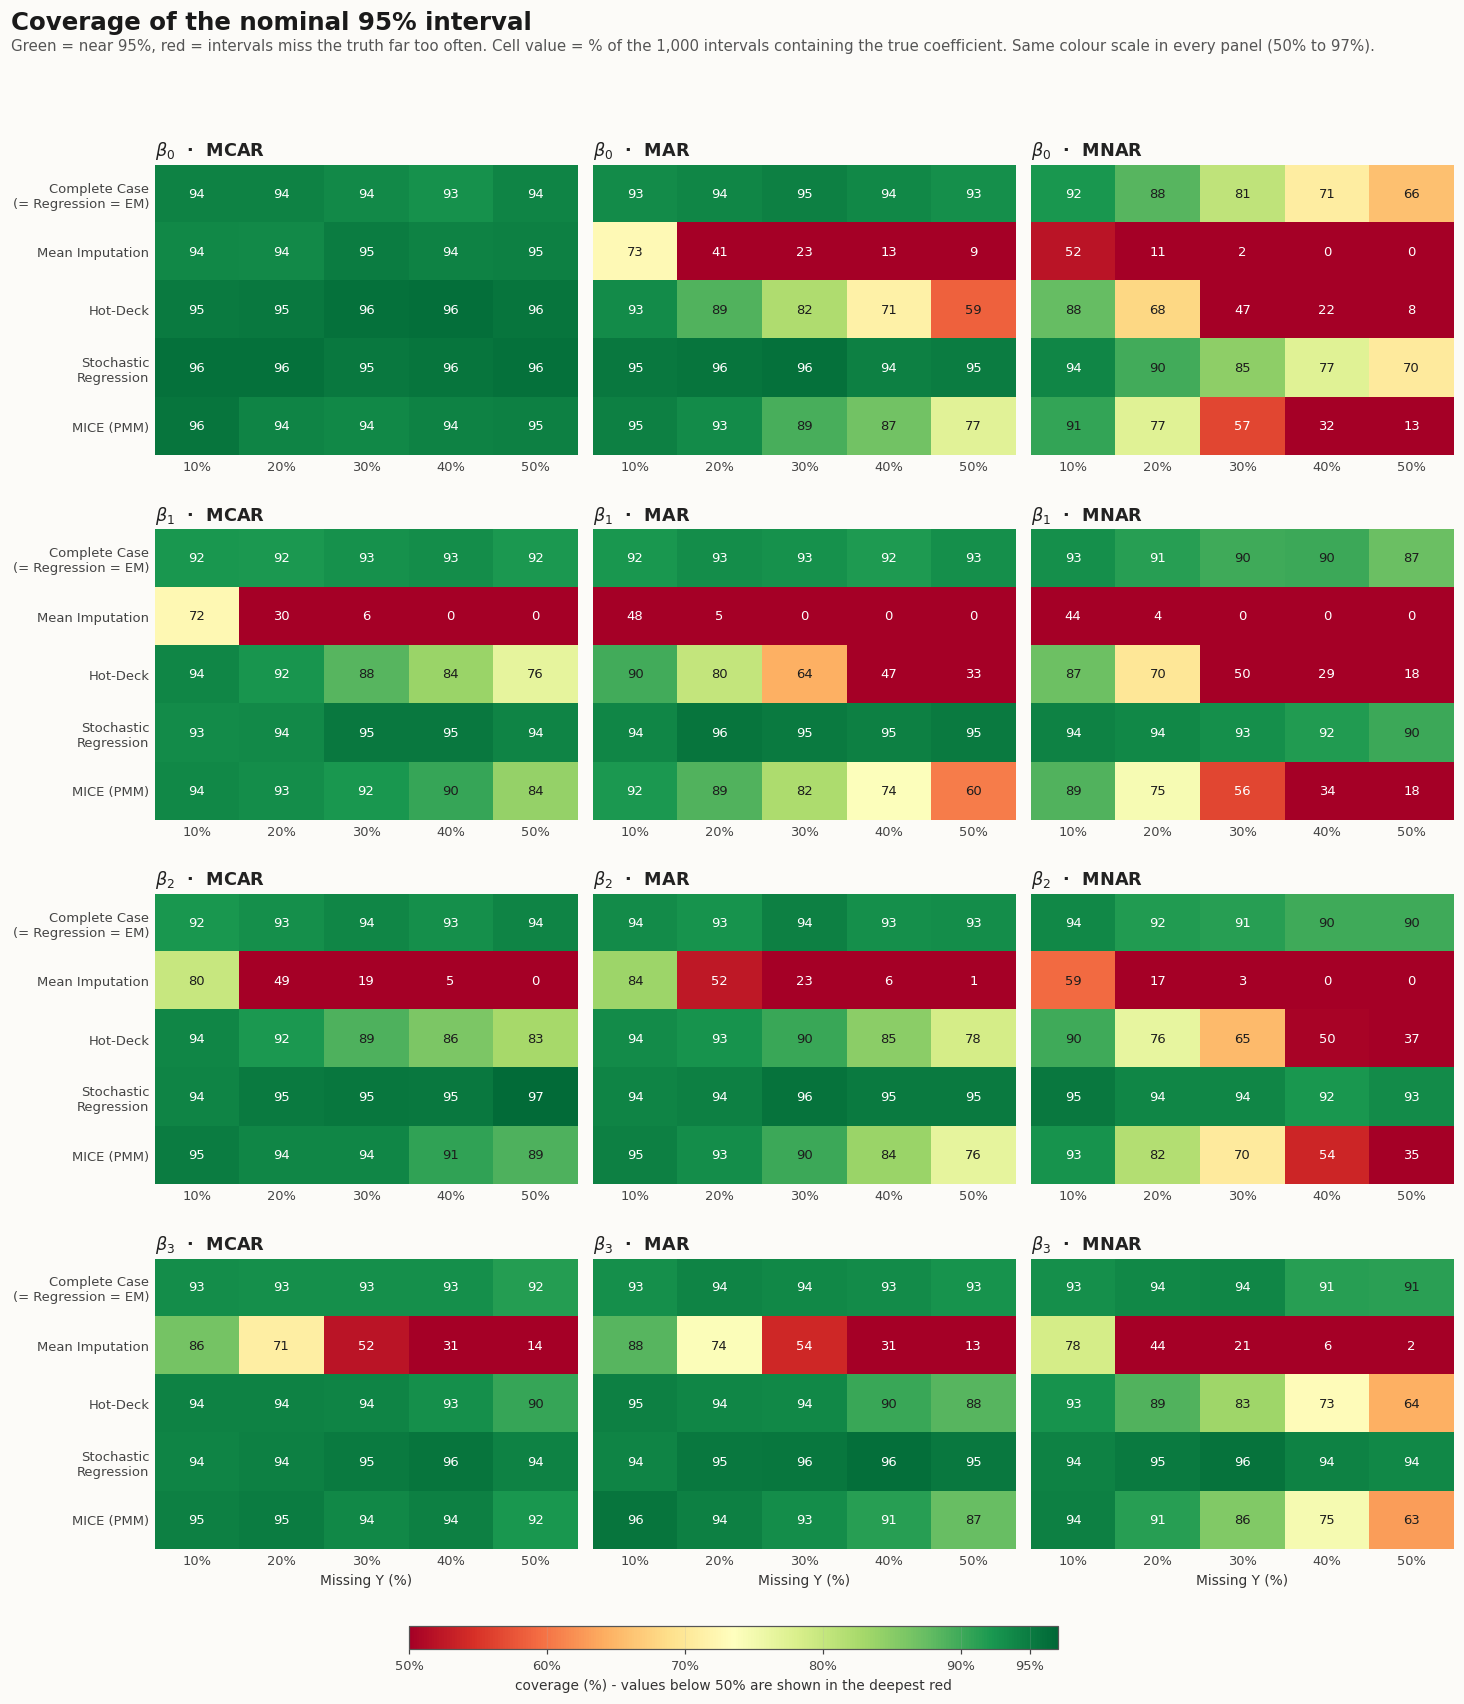

'part2B_outputs/figures/fig13_coverage_heatmaps.png'

In [10]:
# 3.3  Coverage heatmaps
heat_grid("coverage", "Coverage of the nominal 95% interval",
          "Green = near 95%, red = intervals miss the truth far too often. Cell value = % of the 1,000 intervals containing the true coefficient. Same colour scale in every panel (50% to 97%).",
          "RdYlGn", Normalize(vmin=0.50, vmax=0.97), "{:.0%}", "fig13_coverage_heatmaps",
          textfn=lambda v: f"{100 * v:.0f}", cbar_label="coverage (%) - values below 50% are shown in the deepest red",
          ticks=[0.5, 0.6, 0.7, 0.8, 0.9, 0.95], cbar_fmt=mtick.PercentFormatter(1.0, decimals=0))

### 3.4 Rank tables
For each mechanism, severity level and coefficient we rank the five methods by RMSE (1 = smallest). Because every method is run on the **same datasets with the same deletions**, we can also ask the paired question *"is this method really worse than the best one, or is it a tie within Monte Carlo error?"*: a method **ties** the best if the paired difference in squared error against the best method has $z<2$. Ties are marked **\***.

Two summaries follow: the rank **within each coefficient** (with ties), and the **worst-coefficient** rank, based on each method's largest RMSE ratio over β₀…β₃ (the "weakest link" view used in the decision guide).

In [11]:
# 3.4  Rank tables with paired "ties the best" test
rank_rows = []
for c in COEFS:
    for mi, mech in enumerate(MECHS):
        for si, s in enumerate(LEVELS):
            mse = MA[c]["rmse"][mi, si] ** 2
            best = int(np.argmin(mse))
            sq = ERR[c][:, mi, si, :] ** 2                                  # (R, F)
            diff = sq - sq[:, [best]]
            z = diff.mean(0) / np.where(diff.std(0, ddof=1) == 0, np.nan, diff.std(0, ddof=1) / np.sqrt(R))
            order = stats.rankdata(MA[c]["rmse"][mi, si], method="min")
            for fi, f in enumerate(FAMS):
                rank_rows.append({"coef": c, "mechanism": mech, "severity": s, "method": f, "rmse": MA[c]["rmse"][mi, si, fi],
                                  "rank": int(order[fi]), "ties_best": bool(fi == best or not (z[fi] >= TIE_Z))})
ranks = pd.DataFrame(rank_rows)
save_table(ranks, "ranks_by_coefficient", index=False)

# worst-coefficient view: each method's largest RMSE ratio / smallest coverage over the four coefficients
wr = np.max(np.stack([MA[c]["rmse_ratio"] for c in COEFS]), axis=0)          # (M, S, F)
wc = np.min(np.stack([MA[c]["coverage"] for c in COEFS]), axis=0)
wsb = np.max(np.stack([np.abs(MA[c]["std_bias"]) for c in COEFS]), axis=0)
worst_rows = []
for mi, mech in enumerate(MECHS):
    for si, s in enumerate(LEVELS):
        rk = stats.rankdata(wr[mi, si], method="min")
        for fi, f in enumerate(FAMS):
            worst_rows.append({"mechanism": mech, "severity": s, "method": f, "worst_rmse_ratio": wr[mi, si, fi], "worst_coverage": wc[mi, si, fi],
                               "worst_std_bias": wsb[mi, si, fi], "rank_worst": int(rk[fi])})
worst = pd.DataFrame(worst_rows)
save_table(worst, "worst_coefficient_summary", index=False)

def rank_display(df, levels=(10, 30, 50)):
    t = df[df["severity"].isin(levels)].copy()
    t["col"] = t["mechanism"] + " @" + t["severity"].astype(str) + "%"
    p = t.pivot_table(index="method", columns="col", values="rank_worst", aggfunc="first").reindex(FAMS)
    p = p[[f"{m} @{s}%" for m in MECHS for s in levels]]; p.index = [FLAB1[f] for f in p.index]
    return p
display(Markdown("#### Worst-coefficient rank (1 = best; judged by each method's largest RMSE ratio over β₀…β₃)"))
rk_tab = save_table(rank_display(worst), "rank_worst_coefficient_10_30_50"); display(rk_tab)

display(Markdown("#### Rank within each coefficient at 50% missingness  (\\* = statistically tied with the best, paired test)"))
t = ranks[ranks["severity"] == 50].copy()
t["cell"] = t["rank"].astype(str) + np.where(t["ties_best"] & (t["rank"] > 1), "*", "")
p = t.pivot_table(index=["coef", "method"], columns="mechanism", values="cell", aggfunc="first")[MECHS]
p = p.reindex(pd.MultiIndex.from_product([COEFS, FAMS], names=["coef", "method"]))
p.index = pd.MultiIndex.from_tuples([(CNAME[a], FLAB1[b]) for a, b in p.index], names=["coef", "method"])
save_table(p, "rank_by_coefficient_at_50pct"); display(p)

# average rank over the five severity levels, per mechanism (how often is each method near the top?)
avg = worst.groupby(["mechanism", "method"])["rank_worst"].mean().unstack(0).reindex(FAMS)[MECHS]; avg.index = [FLAB1[f] for f in avg.index]
display(Markdown("#### Average worst-coefficient rank over the five severity levels"))
save_table(avg.round(2), "rank_worst_average_over_levels"); display(avg.round(2))

#### Worst-coefficient rank (1 = best; judged by each method's largest RMSE ratio over β₀…β₃)

col,MCAR @10%,MCAR @30%,MCAR @50%,MAR @10%,MAR @30%,MAR @50%,MNAR @10%,MNAR @30%,MNAR @50%
Complete Case (= Regression = EM),1,1,1,1,1,1,1,1,1
Mean Imputation,5,5,5,5,5,5,5,5,5
Hot-Deck,4,4,4,4,4,4,4,4,4
Stochastic Regression,3,3,2,2,2,2,2,2,2
MICE (PMM),2,2,3,3,3,3,3,3,3


#### Rank within each coefficient at 50% missingness  (\* = statistically tied with the best, paired test)

mechanism                               MCAR MAR MNAR
coef  method                                         
beta0 Complete Case (= Regression = EM)    1   1    1
      Mean Imputation                      5   5    5
      Hot-Deck                             4   4    4
      Stochastic Regression                2   2    2
      MICE (PMM)                           3   3    3
beta1 Complete Case (= Regression = EM)    1   1    1
      Mean Imputation                      5   5    5
      Hot-Deck                             4   4    4
      Stochastic Regression                2   2    2
      MICE (PMM)                           3   3    3
beta2 Complete Case (= Regression = EM)    1   1    1
      Mean Imputation                      5   5    5
      Hot-Deck                             4   4    4
      Stochastic Regression                2   2    2
      MICE (PMM)                           3   3    3
beta3 Complete Case (= Regression = EM)    1   1    1
      Mean Imputation                      5   5    5
      Hot-Deck                             4   4    4
      Stochastic Regression                2   2    2
      MICE (PMM)                           3   3    3

#### Average worst-coefficient rank over the five severity levels

mechanism,MCAR,MAR,MNAR
Complete Case (= Regression = EM),1.0,1.0,1.0
Mean Imputation,5.0,5.0,5.0
Hot-Deck,4.0,4.0,4.0
Stochastic Regression,2.6,2.0,2.0
MICE (PMM),2.4,3.0,3.0


---
## Section 4 · Breaking points

### 4.1 Definition
A **breaking point** is the missingness level at which a method first crosses a pre-set line, for a given mechanism and coefficient:

* **Coverage breaks** when 95%-interval coverage falls **below 90%** (`COVER_FLOOR`).
* **Bias becomes material** when $\lvert\text{bias}\rvert \ge 0.5\times\text{SD}_\text{Full}$ of that coefficient (`STD_BIAS_MATERIAL`).

Only five levels were simulated (10, 20, …, 50%), so the table gives two things: the **first tested level** at which the line is crossed, and a **linearly interpolated crossing point** between the grid levels, anchored at 0% missingness where every method equals the Full-Data analysis. The interpolation is an estimate, so each crossing carries a **95% interval from a replicate bootstrap** (resample the 1,000 replicates with replacement, recompute everything, including the Full-Data anchor, 1,000 times). `>50` means the line was not crossed within the tested range; `p(break)` is the share of bootstrap resamples that did cross, so a value well below 1 says "close call".

In [12]:
# 4.2  Breaking points with replicate-bootstrap intervals
LEV0 = np.array([0.0] + [float(s) for s in LEVELS])

def crossing(score):
    """score: (..., 6) over [anchor, 10..50]; a level 'breaches' when score > 0.
    Returns the linearly interpolated severity at which score crosses 0 (nan if never within 50%)."""
    breach = score > 0
    anyb = breach.any(-1)
    first = np.where(anyb, breach.argmax(-1), 0)
    i0 = np.maximum(first - 1, 0)
    s0 = np.take_along_axis(score, i0[..., None], -1)[..., 0]
    s1 = np.take_along_axis(score, first[..., None], -1)[..., 0]
    x0, x1 = LEV0[i0], LEV0[first]
    with np.errstate(divide="ignore", invalid="ignore"):
        x = x0 + (0.0 - s0) / (s1 - s0) * (x1 - x0)
    x = np.where(first == 0, 0.0, x)
    return np.where(anyb, x, np.nan)

rng = np.random.default_rng(BOOT_SEED)
COUNTS = rng.multinomial(R, np.ones(R) / R, size=N_BOOT).astype(float)         # (B, R) resampling weights
ONES = np.ones((1, R))

def curves(c, mi, W):
    """Coverage and |standardised bias| curves (with the 0% anchor) for resampling weights W (B, R): shapes (B, F, 6)."""
    covc = np.concatenate([FCOV[c][:, None, None] * np.ones((1, 1, F_)), COV[c][:, mi]], axis=1)         # (R, 6, F)
    errc = np.concatenate([FERR[c][:, None, None] * np.ones((1, 1, F_)), ERR[c][:, mi]], axis=1)
    cov = np.einsum("br,rsf->bsf", W, covc) / R
    bias = np.einsum("br,rsf->bsf", W, errc) / R
    m1 = W @ FERR[c] / R; m2 = W @ (FERR[c] ** 2) / R
    sdf = np.sqrt(np.maximum(m2 - m1 ** 2, 1e-18) * R / (R - 1))                  # SD of the Full-Data estimator in each resample
    sbias = np.abs(bias) / sdf[:, None, None]
    return cov.transpose(0, 2, 1), sbias.transpose(0, 2, 1)

bp_rows = []
for c in COEFS:
    for mi, mech in enumerate(MECHS):
        cov_pt, sb_pt = curves(c, mi, ONES)
        cov_bt, sb_bt = curves(c, mi, COUNTS)
        for crit, pt, bt, sc in (("coverage", cov_pt, cov_bt, lambda a: COVER_FLOOR - a),
                                 ("bias", sb_pt, sb_bt, lambda a: a - STD_BIAS_MATERIAL)):
            x_pt = crossing(sc(pt))[0]                                             # (F,)
            x_bt = crossing(sc(bt))                                                # (B, F)
            first_level = [(LEVELS[int(np.argmax(sc(pt)[0, f, 1:] > 0))] if (sc(pt)[0, f, 1:] > 0).any() else np.nan) for f in range(F_)]
            for fi, f in enumerate(FAMS):
                b = x_bt[:, fi]; ok = np.isfinite(b)
                bp_rows.append({"criterion": crit, "coef": c, "mechanism": mech, "method": f, "first_level_breached": first_level[fi],
                                "bp": x_pt[fi], "lo": np.percentile(b[ok], 2.5) if ok.mean() > 0.5 else np.nan,
                                "hi": np.percentile(b[ok], 97.5) if ok.mean() > 0.5 else np.nan, "p_break": ok.mean()})
bp = pd.DataFrame(bp_rows)
save_table(bp, "breaking_points", index=False)

def bp_cell(r):
    if not np.isfinite(r["bp"]): return ">50" + (f" (p={r['p_break']:.2f})" if r["p_break"] > 0.05 else "")
    ci = f" [{r['lo']:.0f}-{r['hi']:.0f}]" if np.isfinite(r["lo"]) else ""
    return f"{r['bp']:.0f}{ci}"
bp["cell"] = bp.apply(bp_cell, axis=1)
print(f"Breaking-point table: {len(bp)} rows; bootstrap B = {N_BOOT}")
# sanity: bootstrap resamples reproduce the point estimate on average
cp, _ = curves("b1", 0, ONES); cb_, _ = curves("b1", 0, COUNTS)
record("4", "Replicate-bootstrap coverage curves are centred on the observed curves (mean abs gap < 0.01)", float(np.abs(cb_.mean(0) - cp[0]).max()) < 0.01,
       f"max gap {float(np.abs(cb_.mean(0) - cp[0]).max()):.4f}")

Breaking-point table: 120 rows; bootstrap B = 1000
PASS  [4] Replicate-bootstrap coverage curves are centred on the observed curves (mean abs gap < 0.01)  ->  max gap 0.0003


### 4.3 The breaking-point tables
Each cell shows the **interpolated breaking level in % missing** with its 95% bootstrap interval in brackets. Read `>50` as "survived everything tested". A value of `5 [2-8]` means the line was crossed *before the first tested level*, i.e. the method is already outside the line at 10%.

In [13]:
# 4.3  Tables
def bp_table(crit):
    t = bp[bp["criterion"] == crit]
    p = t.pivot_table(index=["coef", "method"], columns="mechanism", values="cell", aggfunc="first")[MECHS]
    p = p.reindex(pd.MultiIndex.from_product([COEFS, FAMS], names=["coef", "method"]))
    p.index = pd.MultiIndex.from_tuples([(CNAME[a], FLAB1[b]) for a, b in p.index], names=["coef", "method"])
    return p
bp_cov = save_table(bp_table("coverage"), "breaking_point_coverage_below_90")
bp_bias = save_table(bp_table("bias"), "breaking_point_material_bias")
display(Markdown("#### Coverage drops below 90% at (% missing)"));  display(bp_cov)
display(Markdown("#### Bias becomes material (≥ 0.5 SD of the Full-Data estimator) at (% missing)"));  display(bp_bias)

# the 'weakest link' view: the earliest breaking point over the four coefficients
def weakest(crit):
    t = bp[bp["criterion"] == crit].copy(); t["bp_f"] = t["bp"].fillna(np.inf)
    g = t.loc[t.groupby(["mechanism", "method"])["bp_f"].idxmin()]
    g = g.assign(which=g["coef"].map(CNAME), val=np.where(np.isfinite(g["bp"]), g["bp"].round(0).astype("float"), np.nan))
    p = g.pivot(index="method", columns="mechanism", values="bp")[MECHS].reindex(FAMS)
    w = g.pivot(index="method", columns="mechanism", values="which")[MECHS].reindex(FAMS)
    out = pd.DataFrame({m: [(f">50" if not np.isfinite(p.loc[f, m]) else f"{p.loc[f, m]:.0f} ({w.loc[f, m]})") for f in FAMS] for m in MECHS}, index=[FLAB1[f] for f in FAMS])
    return out
display(Markdown("#### Weakest link: earliest coverage break over the four coefficients (the coefficient that breaks first is in brackets)"))
wl_cov = save_table(weakest("coverage"), "weakest_link_coverage_break"); display(wl_cov)
display(Markdown("#### Weakest link: earliest material-bias point over the four coefficients"))
wl_bias = save_table(weakest("bias"), "weakest_link_material_bias"); display(wl_bias)

#### Coverage drops below 90% at (% missing)

mechanism                                        MCAR         MAR  \
coef  method                                                        
beta0 Complete Case (= Regression = EM)           >50         >50   
      Mean Imputation                             >50     2 [2-3]   
      Hot-Deck                                    >50  18 [14-21]   
      Stochastic Regression                       >50         >50   
      MICE (PMM)                                  >50  28 [24-34]   
beta1 Complete Case (= Regression = EM)           >50         >50   
      Mean Imputation                         2 [1-3]     1 [1-1]   
      Hot-Deck                             26 [22-31]    9 [6-12]   
      Stochastic Regression                       >50         >50   
      MICE (PMM)                           41 [34-43]  17 [11-21]   
beta2 Complete Case (= Regression = EM)           >50         >50   
      Mean Imputation                         3 [3-4]     4 [3-6]   
      Hot-Deck                             27 [22-33]  31 [25-34]   
      Stochastic Regression                       >50         >50   
      MICE (PMM)                           45 [37-49]  30 [25-33]   
beta3 Complete Case (= Regression = EM)           >50         >50   
      Mean Imputation                         6 [4-8]    8 [5-10]   
      Hot-Deck                           >50 (p=0.27)  42 [36-48]   
      Stochastic Regression                       >50         >50   
      MICE (PMM)                                  >50  44 [39-48]   

mechanism                                        MNAR  
coef  method                                           
beta0 Complete Case (= Regression = EM)    16 [11-21]  
      Mean Imputation                         1 [1-2]  
      Hot-Deck                                7 [5-9]  
      Stochastic Regression                20 [16-23]  
      MICE (PMM)                            10 [8-12]  
beta1 Complete Case (= Regression = EM)    40 [19-46]  
      Mean Imputation                         1 [1-1]  
      Hot-Deck                                6 [4-8]  
      Stochastic Regression              >50 (p=0.43)  
      MICE (PMM)                             8 [5-11]  
beta2 Complete Case (= Regression = EM)    39 [19-48]  
      Mean Imputation                         1 [1-2]  
      Hot-Deck                              10 [7-11]  
      Stochastic Regression                       >50  
      MICE (PMM)                           12 [11-14]  
beta3 Complete Case (= Regression = EM)  >50 (p=0.13)  
      Mean Imputation                         3 [2-4]  
      Hot-Deck                             17 [13-21]  
      Stochastic Regression                       >50  
      MICE (PMM)                           22 [19-25]

#### Bias becomes material (≥ 0.5 SD of the Full-Data estimator) at (% missing)

mechanism                                      MCAR         MAR        MNAR
coef  method                                                               
beta0 Complete Case (= Regression = EM)         >50         >50  13 [11-15]
      Mean Imputation                           >50     3 [2-3]     2 [2-2]
      Hot-Deck                                  >50  14 [12-16]     6 [5-7]
      Stochastic Regression                     >50         >50  13 [11-15]
      MICE (PMM)                                >50  24 [21-26]     8 [7-9]
beta1 Complete Case (= Regression = EM)         >50         >50  28 [23-32]
      Mean Imputation                       2 [2-3]     1 [1-2]     1 [1-2]
      Hot-Deck                           20 [17-22]     7 [6-8]     6 [5-6]
      Stochastic Regression                     >50         >50  27 [22-31]
      MICE (PMM)                         32 [30-35]  15 [13-17]     8 [7-9]
beta2 Complete Case (= Regression = EM)         >50         >50  32 [27-38]
      Mean Imputation                       3 [3-4]     3 [3-4]     2 [2-2]
      Hot-Deck                           21 [18-24]  20 [17-23]     8 [7-8]
      Stochastic Regression                     >50         >50  34 [28-39]
      MICE (PMM)                         34 [30-38]  22 [20-24]   10 [8-11]
beta3 Complete Case (= Regression = EM)         >50         >50  42 [36-49]
      Mean Imputation                       5 [4-5]     5 [4-6]     3 [2-3]
      Hot-Deck                           30 [25-34]  26 [21-30]   11 [9-12]
      Stochastic Regression                     >50         >50  39 [35-47]
      MICE (PMM)                         44 [40-48]  28 [25-31]  13 [12-15]

#### Weakest link: earliest coverage break over the four coefficients (the coefficient that breaks first is in brackets)

,MCAR,MAR,MNAR
Complete Case (= Regression = EM),>50,>50,16 (beta0)
Mean Imputation,2 (beta1),1 (beta1),1 (beta1)
Hot-Deck,26 (beta1),9 (beta1),6 (beta1)
Stochastic Regression,>50,>50,20 (beta0)
MICE (PMM),41 (beta1),17 (beta1),8 (beta1)


#### Weakest link: earliest material-bias point over the four coefficients

,MCAR,MAR,MNAR
Complete Case (= Regression = EM),>50,>50,13 (beta0)
Mean Imputation,2 (beta1),1 (beta1),1 (beta1)
Hot-Deck,20 (beta1),7 (beta1),6 (beta1)
Stochastic Regression,>50,>50,13 (beta0)
MICE (PMM),32 (beta1),15 (beta1),8 (beta0)


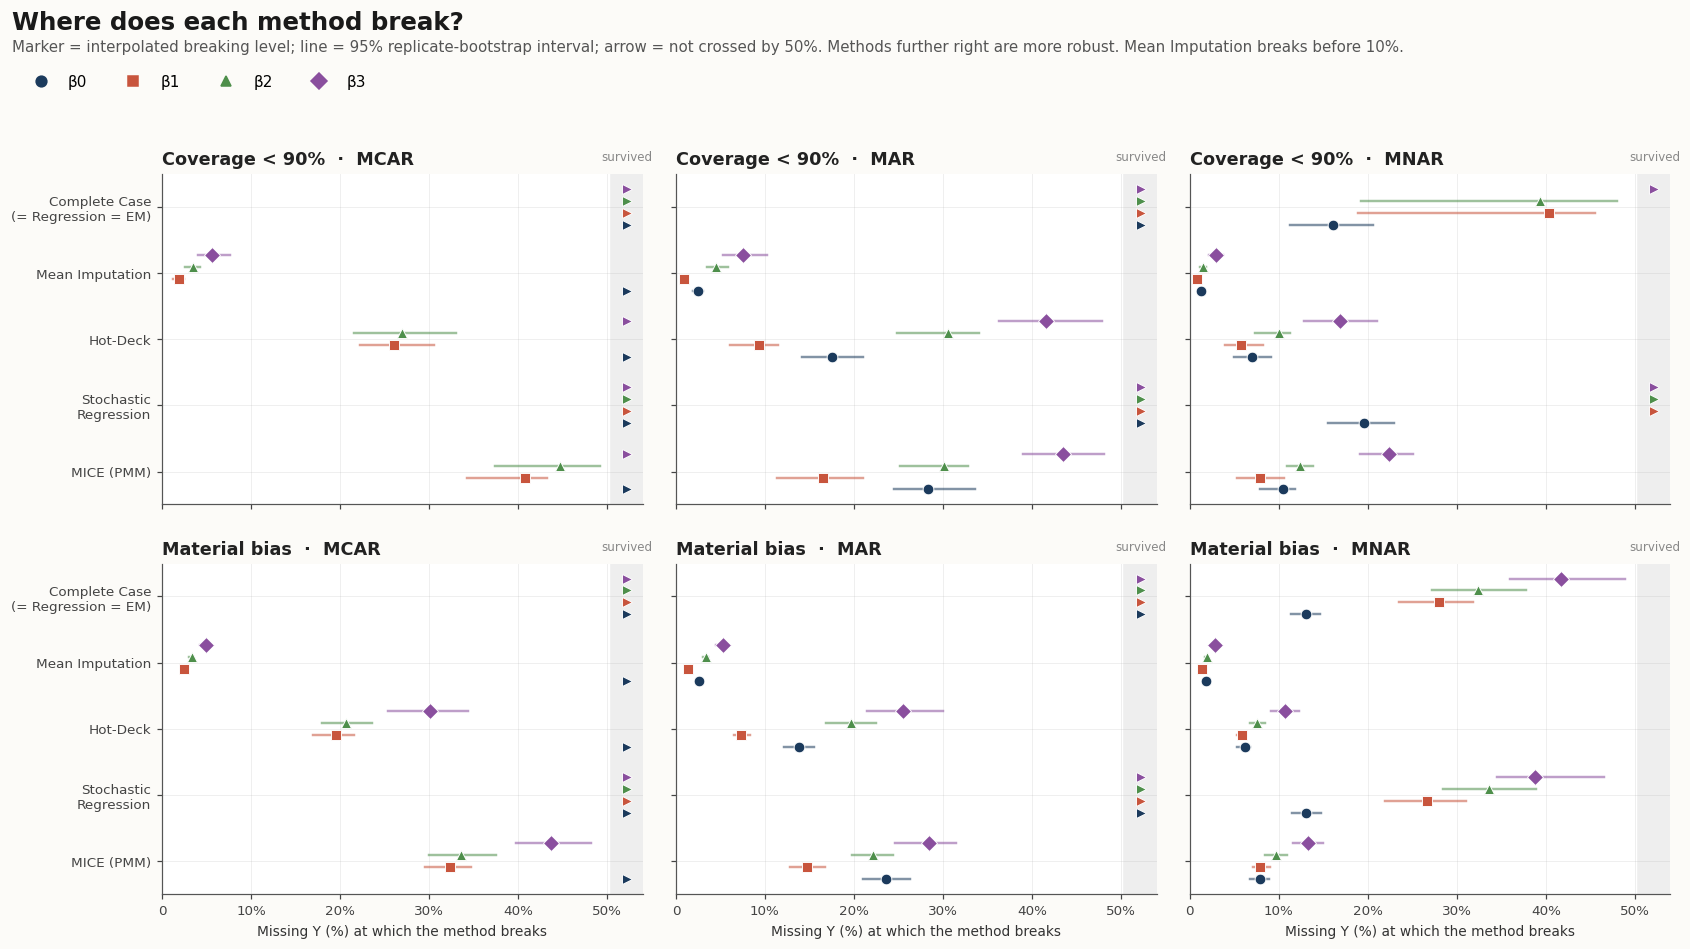

'part2B_outputs/figures/fig14_breaking_points.png'

In [14]:
# 4.4  Figure: breaking points (rows = method, 4 markers = coefficients; panels = criterion x mechanism)
def bp_figure():
    fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.6), facecolor=FIG_BG, sharex=True)
    ypos = {f: i for i, f in enumerate(FAMS[::-1])}
    off = {"b0": -0.27, "b1": -0.09, "b2": 0.09, "b3": 0.27}
    for r_, crit in enumerate(("coverage", "bias")):
        for mi, mech in enumerate(MECHS):
            ax = axes[r_, mi]
            t = bp[(bp["criterion"] == crit) & (bp["mechanism"] == mech)]
            for _, row in t.iterrows():
                y = ypos[row["method"]] + off[row["coef"]]
                if np.isfinite(row["bp"]):
                    if np.isfinite(row["lo"]): ax.plot([row["lo"], row["hi"]], [y, y], color=CPAL[row["coef"]], lw=1.6, alpha=0.55, zorder=2)
                    ax.plot(row["bp"], y, marker=CMARK[row["coef"]], color=CPAL[row["coef"]], ms=7, zorder=3, mec="white", mew=0.6)
                else:
                    ax.plot(52.2, y, marker=">", color=CPAL[row["coef"]], ms=7, zorder=3, mec="white", mew=0.6)
            ax.set_yticks(list(ypos.values())); ax.set_yticklabels([FLAB[f] for f in ypos], fontsize=8.8) if mi == 0 else ax.set_yticklabels([])
            ax.set_xlim(0, 54); ax.set_xticks([0] + LEVELS); ax.set_xticklabels(["0"] + [f"{s}%" for s in LEVELS], fontsize=8.8)
            ax.axvspan(50.4, 54, color="#EEEEEE", zorder=0); ax.set_facecolor("white")
            ax.text(52.2, len(FAMS) - 0.35, "survived", ha="center", va="bottom", fontsize=7.8, color="#888888")
            ax.set_title(("Coverage < 90%" if crit == "coverage" else "Material bias") + f"  ·  {mech}", loc="left", fontsize=11.5, fontweight="bold", color="#222222")
            if r_ == 1: ax.set_xlabel("Missing Y (%) at which the method breaks", fontsize=9)
    h = [Line2D([0], [0], marker=CMARK[c], color=CPAL[c], lw=0, ms=7, label=CNAME[c].replace("beta", "β")) for c in COEFS]
    fig.legend(handles=h, loc="upper left", bbox_to_anchor=(0.01, 0.945), ncol=4, frameon=False, fontsize=10)
    fig.suptitle("Where does each method break?", x=0.01, y=0.998, ha="left", fontsize=16, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.955, "Marker = interpolated breaking level; line = 95% replicate-bootstrap interval; arrow = not crossed by 50%. Methods further right are more robust. Mean Imputation breaks before 10%.",
             fontsize=9.8, color="#555555")
    fig.tight_layout(rect=[0, 0, 1, 0.91], h_pad=2.0, w_pad=1.0)
    return savefig(fig, "fig14_breaking_points")
bp_figure()

---
## Section 5 · Method × mechanism interaction: who is robust, who is not

### 5.1 The question
Section 2 asked what a mechanism does to *each method*. The sharper question is whether it does the **same thing to every method**. If it does, mechanism and method act separately; if not, there is an **interaction**: some methods are robust to a mechanism and others are not.

We measure it with a **difference-in-differences against Complete Case**, replicate by replicate:

$$\text{DiD}_{m} \;=\; \overline{\big(\hat\beta^{\,\text{mech}}_{m}-\hat\beta^{\,\text{MCAR}}_{m}\big)-\big(\hat\beta^{\,\text{mech}}_{\text{CC}}-\hat\beta^{\,\text{MCAR}}_{\text{CC}}\big)}$$

(the same for the coverage indicator). Complete Case is the natural yardstick because, with only $Y$ missing and $X$ always observed, it is valid under MAR by theory. A DiD near 0 means "this method reacts to the mechanism exactly as Complete Case does". A clearly non-zero DiD under **MAR** is the interesting case: a method that should handle MAR but is hurt by it more than the simple benchmark.

In [15]:
# 5.2  Difference-in-differences against Complete Case
did_rows = []
for c in COEFS:
    for mi in (1, 2):
        dm_b = ERR[c][:, mi] - ERR[c][:, 0]                      # (R, S, F)  mechanism effect on the signed error
        dm_c = COV[c][:, mi] - COV[c][:, 0]
        for nm, dm in (("bias", dm_b), ("cov", dm_c)):
            did = dm[:, :, 1:] - dm[:, :, [0]]                    # each non-CC method minus Complete Case
            mean, se = did.mean(0), did.std(0, ddof=1) / np.sqrt(R)
            for si, s in enumerate(LEVELS):
                for k, f in enumerate(FAMS[1:]):
                    did_rows.append({"measure": nm, "coef": c, "mechanism": MECHS[mi], "severity": s, "method": f,
                                     "did": mean[si, k], "se": se[si, k], "z": mean[si, k] / se[si, k] if se[si, k] > 0 else np.nan})
did = pd.DataFrame(did_rows)
save_table(did, "interaction_did_vs_complete_case", index=False)

def did_cell(r, scale, dec): return f"{r['did'] * scale:+.{dec}f}{star(r['z'])}"
for nm, scale, dec, ttl in (("bias", 1, 3, "Interaction in BIAS at 50%: extra change vs MCAR, relative to Complete Case"),
                            ("cov", 100, 1, "Interaction in COVERAGE at 50% (percentage points): extra change vs MCAR, relative to Complete Case")):
    t = did[(did["measure"] == nm) & (did["severity"] == 50)].copy()
    t["cell"] = t.apply(lambda r: did_cell(r, scale, dec), axis=1)
    p = t.pivot_table(index=["coef", "method"], columns="mechanism", values="cell", aggfunc="first")[["MAR", "MNAR"]]
    p = p.reindex(pd.MultiIndex.from_product([COEFS, FAMS[1:]], names=["coef", "method"]))
    p.index = pd.MultiIndex.from_tuples([(CNAME[a], FLAB1[b]) for a, b in p.index], names=["coef", "method"])
    save_table(p, f"interaction_{nm}_at_50pct"); display(Markdown(f"#### {ttl}  (✱ = |z| > {Z_FLAG:g})")); display(p)

#### Interaction in BIAS at 50%: extra change vs MCAR, relative to Complete Case  (✱ = |z| > 3)

mechanism                        MAR     MNAR
coef  method                                 
beta0 Mean Imputation        +1.044✱  -1.242✱
      Hot-Deck               +0.310✱  -0.355✱
      Stochastic Regression   -0.002   -0.000
      MICE (PMM)             +0.182✱  -0.271✱
beta1 Mean Imputation        -0.326✱  -0.204✱
      Hot-Deck               -0.279✱  -0.223✱
      Stochastic Regression   -0.003   +0.002
      MICE (PMM)             -0.161✱  -0.238✱
beta2 Mean Imputation         -0.001  +0.155✱
      Hot-Deck               +0.021✱  +0.160✱
      Stochastic Regression   -0.003   -0.002
      MICE (PMM)             +0.089✱  +0.182✱
beta3 Mean Imputation         -0.007  -0.115✱
      Hot-Deck               -0.027✱  -0.116✱
      Stochastic Regression   -0.003   -0.003
      MICE (PMM)             -0.060✱  -0.123✱

#### Interaction in COVERAGE at 50% (percentage points): extra change vs MCAR, relative to Complete Case  (✱ = |z| > 3)

mechanism                       MAR    MNAR
coef  method                               
beta0 Mean Imputation        -84.9✱  -66.4✱
      Hot-Deck               -36.1✱  -59.0✱
      Stochastic Regression    +0.0   +2.8✱
      MICE (PMM)             -16.6✱  -53.8✱
beta1 Mean Imputation          -0.9   +5.0✱
      Hot-Deck               -44.5✱  -54.0✱
      Stochastic Regression    -0.1    +0.9
      MICE (PMM)             -24.4✱  -61.4✱
beta2 Mean Imputation          +1.4   +3.8✱
      Hot-Deck                 -3.3  -41.6✱
      Stochastic Regression    -0.7    +1.0
      MICE (PMM)             -11.6✱  -49.6✱
beta3 Mean Imputation          -1.7  -12.0✱
      Hot-Deck                 -3.2  -25.7✱
      Stochastic Regression    -0.1    -0.1
      MICE (PMM)              -6.0✱  -28.9✱

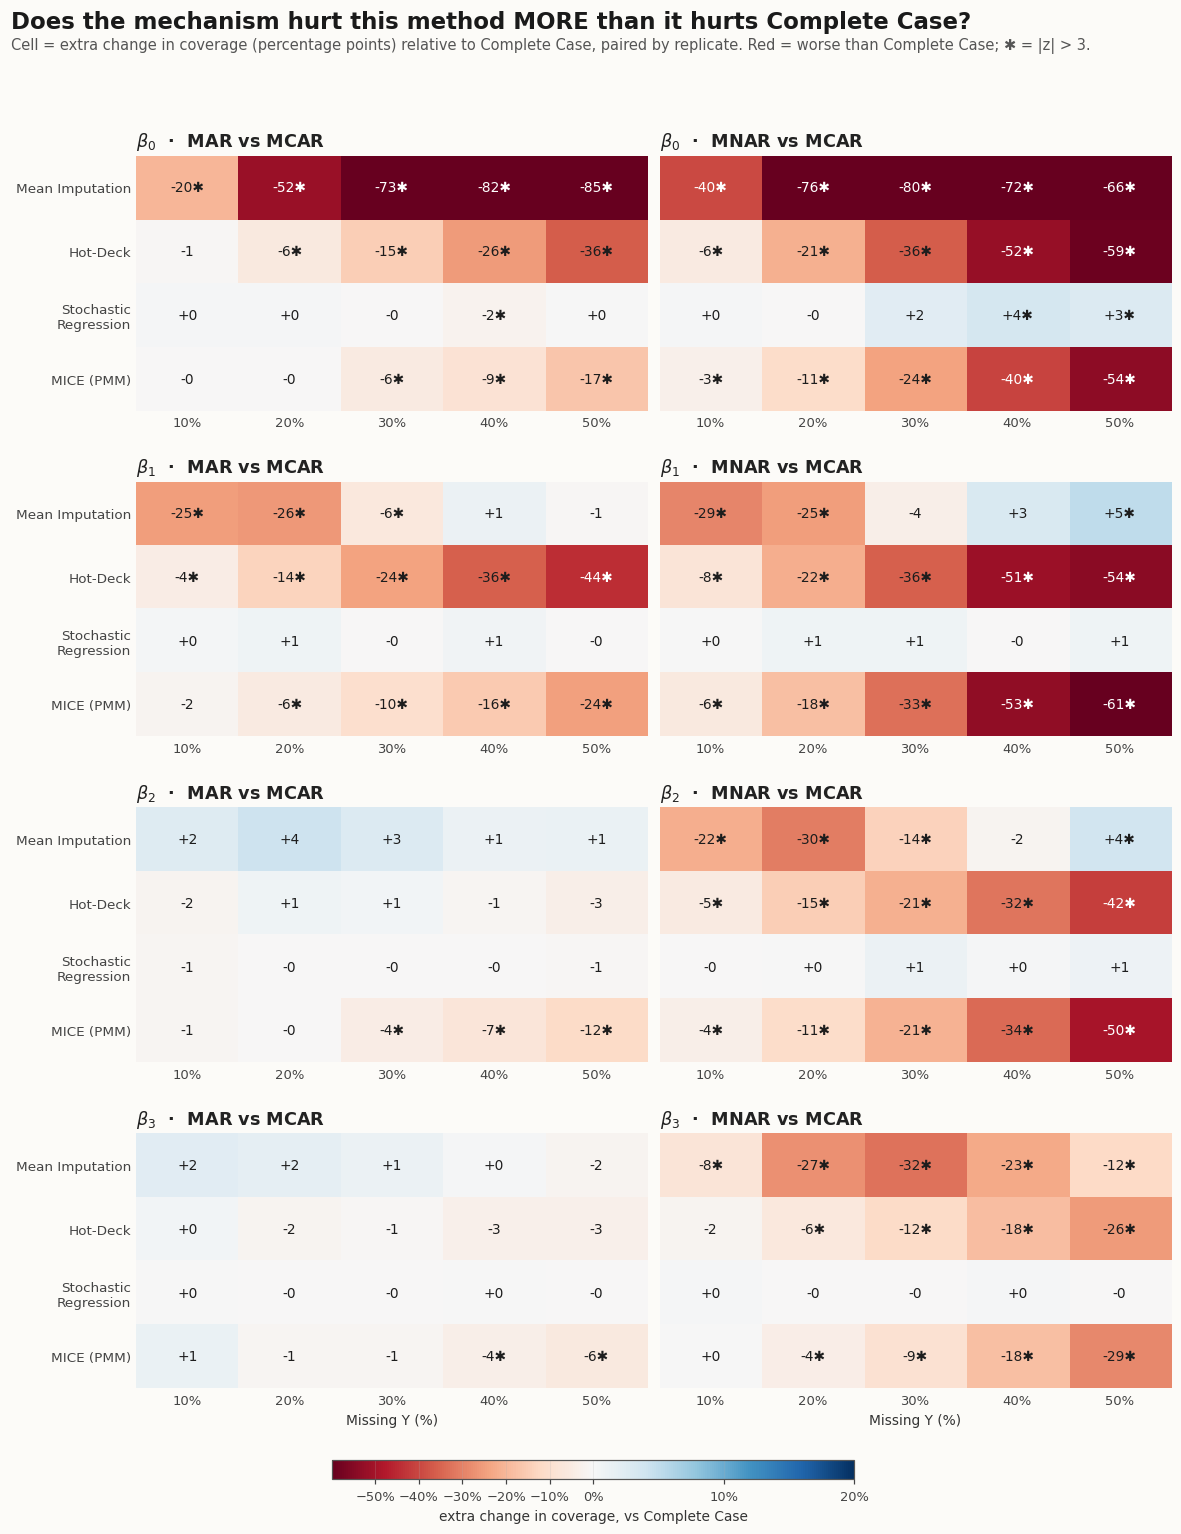

'part2B_outputs/figures/fig15_interaction_coverage.png'

In [16]:
# 5.3  Figure: interaction heatmaps for coverage (rows = coefficients; columns = MAR, MNAR)
def did_figure():
    fig, axes = plt.subplots(4, 2, figsize=(10.8, 13.6), facecolor=FIG_BG)
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-0.60, vmax=0.20); cmap = "RdBu"
    for r_, c in enumerate(COEFS):
        for k, mech in enumerate(("MAR", "MNAR")):
            ax = axes[r_, k]
            t = did[(did["measure"] == "cov") & (did["coef"] == c) & (did["mechanism"] == mech)]
            M = np.array([[t[(t["method"] == f) & (t["severity"] == s)]["did"].iloc[0] for s in LEVELS] for f in FAMS[1:]])
            Z = np.array([[t[(t["method"] == f) & (t["severity"] == s)]["z"].iloc[0] for s in LEVELS] for f in FAMS[1:]])
            ax.imshow(M, cmap=cmap, norm=norm, aspect="auto"); ax.grid(False)
            for i in range(M.shape[0]):
                for j in range(M.shape[1]):
                    rgba = plt.get_cmap(cmap)(norm(M[i, j])); lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                    ax.text(j, i, f"{100 * M[i, j]:+.0f}{'✱' if abs(Z[i, j]) > Z_FLAG else ''}", ha="center", va="center", fontsize=9,
                            color="white" if lum < 0.45 else "#1d1d1d")
            ax.set_xticks(range(5)); ax.set_xticklabels([f"{s}%" for s in LEVELS], fontsize=8.6)
            ax.set_yticks(range(4)); ax.set_yticklabels([FLAB[f] for f in FAMS[1:]] if k == 0 else [], fontsize=8.8)
            ax.tick_params(length=0)
            for sp in ax.spines.values(): sp.set_visible(False)
            ax.set_title(f"{CLAB[c]}  ·  {mech} vs MCAR", loc="left", fontsize=11.5, fontweight="bold", color="#222222", pad=6)
            if r_ == 3: ax.set_xlabel("Missing Y (%)", fontsize=9)
    fig.suptitle("Does the mechanism hurt this method MORE than it hurts Complete Case?", x=0.01, y=0.998, ha="left", fontsize=15, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.972, "Cell = extra change in coverage (percentage points) relative to Complete Case, paired by replicate. Red = worse than Complete Case; ✱ = |z| > 3.",
             fontsize=9.6, color="#555555")
    fig.tight_layout(rect=[0, 0.04, 1, 0.955], h_pad=1.8, w_pad=0.8)
    cax = fig.add_axes([0.28, 0.016, 0.44, 0.013])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
    cb.set_label("extra change in coverage, vs Complete Case", fontsize=9); cb.ax.tick_params(labelsize=8.5)
    cb.ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    return savefig(fig, "fig15_interaction_coverage")
did_figure()

### 5.4 Robustness summary across mechanisms
If you do not know the mechanism (which in real data you cannot test), the sensible question is **"how bad can it get?"** For each method and severity level, the table below takes the **worst case over all three mechanisms and all four coefficients**. The second table turns that into a single number: the **missingness level up to which a method stays inside both lines under every mechanism** (the earliest breaking point over the 12 mechanism × coefficient combinations).

#### Worst-case 95% coverage over all three mechanisms and all four coefficients

severity,10,20,30,40,50
method,,,,,
Complete Case (= Regression = EM),92.3,88.5,80.6,70.9,65.9
Mean Imputation,43.9,4.0,0.1,0.0,0.0
Hot-Deck,87.0,68.0,46.8,21.8,8.5
Stochastic Regression,93.4,89.8,84.6,77.2,70.5
MICE (PMM),88.9,74.6,56.5,31.9,12.6


#### Robust up to: earliest break over 3 mechanisms x 4 coefficients (which coefficient / mechanism breaks first)

,coverage stays >= 90% up to (% missing),bias stays non-material up to (% missing)
Complete Case (= Regression = EM),"16 (beta0, MNAR)","13 (beta0, MNAR)"
Mean Imputation,"1 (beta1, MNAR)","1 (beta1, MNAR)"
Hot-Deck,"6 (beta1, MNAR)","6 (beta1, MNAR)"
Stochastic Regression,"20 (beta0, MNAR)","13 (beta0, MNAR)"
MICE (PMM),"8 (beta1, MNAR)","8 (beta0, MNAR)"


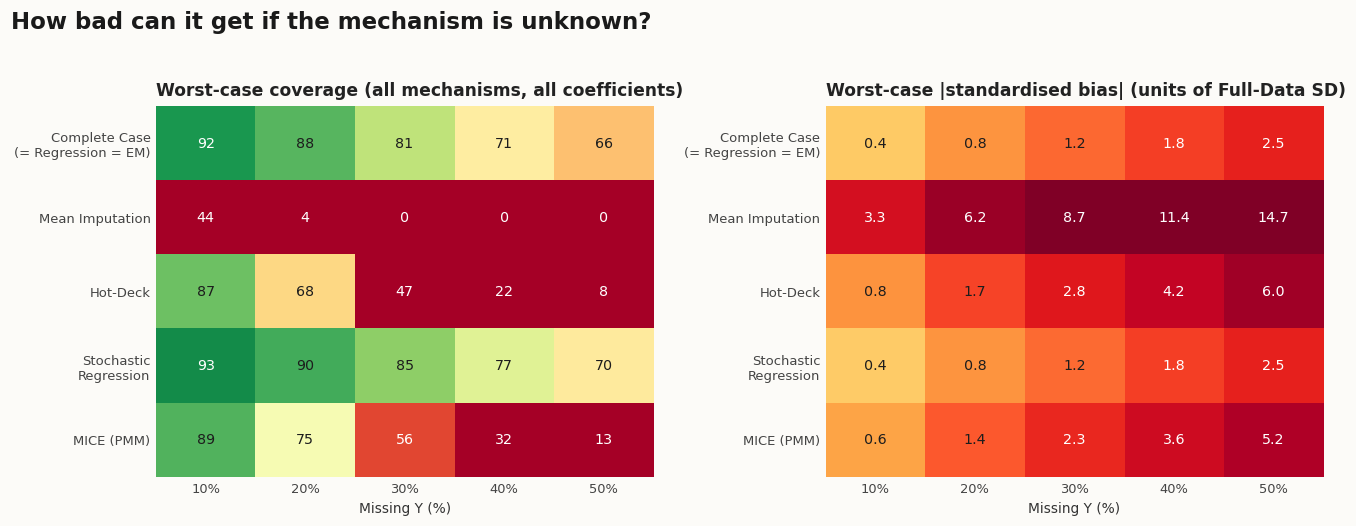

'part2B_outputs/figures/fig16_worst_case_over_mechanisms.png'

In [17]:
# 5.4  Worst case over mechanisms and coefficients
wcov = np.min(np.stack([MA[c]["coverage"] for c in COEFS]), axis=(0, 1))            # (S, F): min over coefficient and mechanism
wsb_all = np.max(np.stack([np.abs(MA[c]["std_bias"]) for c in COEFS]), axis=(0, 1))
wrm = np.max(np.stack([MA[c]["rmse_ratio"] for c in COEFS]), axis=(0, 1))
rob = pd.DataFrame({"method": np.repeat([FLAB1[f] for f in FAMS], len(LEVELS)), "severity": np.tile(LEVELS, F_),
                    "worst_coverage": wcov.T.ravel(), "worst_std_bias": wsb_all.T.ravel(), "worst_rmse_ratio": wrm.T.ravel()})
save_table(rob, "robustness_worst_case_over_mechanisms", index=False)
t = rob.pivot(index="method", columns="severity", values="worst_coverage").reindex([FLAB1[f] for f in FAMS])
display(Markdown("#### Worst-case 95% coverage over all three mechanisms and all four coefficients")); display((100 * t).round(1))

def robust_up_to(crit):
    t = bp[bp["criterion"] == crit].copy(); t["bp_f"] = t["bp"].fillna(np.inf)
    g = t.groupby("method")["bp_f"].min().reindex(FAMS)
    arg = t.loc[t.groupby("method")["bp_f"].idxmin()].set_index("method").reindex(FAMS)
    return pd.Series([">50 (never broke)" if not np.isfinite(g[f]) else f"{g[f]:.0f}  ({CNAME[arg.loc[f, 'coef']]}, {arg.loc[f, 'mechanism']})" for f in FAMS], index=[FLAB1[f] for f in FAMS])
rut = pd.DataFrame({"coverage stays >= 90% up to (% missing)": robust_up_to("coverage"), "bias stays non-material up to (% missing)": robust_up_to("bias")})
display(Markdown("#### Robust up to: earliest break over 3 mechanisms x 4 coefficients (which coefficient / mechanism breaks first)")); display(rut)
save_table(rut, "robust_up_to")

def robust_figure():
    fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6), facecolor=FIG_BG)
    for ax, (arr, ttl, cmap, norm, tf) in zip(axes, [(wcov.T, "Worst-case coverage (all mechanisms, all coefficients)", "RdYlGn", Normalize(0.5, 0.97), lambda v: f"{100 * v:.0f}"),
                                                     (wsb_all.T, "Worst-case |standardised bias| (units of Full-Data SD)", "YlOrRd", LogNorm(0.1, 8.0), lambda v: f"{v:.1f}")]):
        draw_heat(ax, arr, "{:.2f}", cmap, norm, textfn=tf, fs=9.3)
        ax.set_title(ttl, loc="left", fontsize=11.2, fontweight="bold", color="#222222", pad=7); ax.set_xlabel("Missing Y (%)", fontsize=9)
    fig.suptitle("How bad can it get if the mechanism is unknown?", x=0.01, y=1.03, ha="left", fontsize=15, fontweight="bold", color="#1a1a1a")
    fig.tight_layout(w_pad=2.0)
    return savefig(fig, "fig16_worst_case_over_mechanisms")
robust_figure()

---
## Section 6 · Standard-error calibration: are the reported SEs honest?

### 6.1 Two different ways to fail
A 95% interval can miss the truth for **two separate reasons**, and they call for different cures:

1. **The estimate is biased.** The interval is centred in the wrong place. A bigger SE or a better interval would not fix the root cause.
2. **The SE is the wrong size.** The interval is centred correctly but too narrow (overconfident) or too wide (conservative).

Two diagnostics separate them.

* **SE ratio** = (root-mean-square reported SE) ÷ (actual spread of the estimates across replicates). 1.00 is honest, below 1 is overconfident, above 1 conservative. Within 0.90–1.10 is "honest".
* **$z$-scores**: for each replicate $z=(\hat\beta-\beta)/\widehat{SE}$. If estimate and SE are both right, $z$ has **mean 0 and SD 1**. Its **mean** is bias measured in SE units, its **SD** is the calibration of the SE. From (mean, SD) we get two coverage numbers under a normal approximation: coverage **as is**, and coverage **if the bias were removed** (mean set to 0). The gap between the two is the coverage lost to bias; what remains below 95% is the coverage lost to the SE.

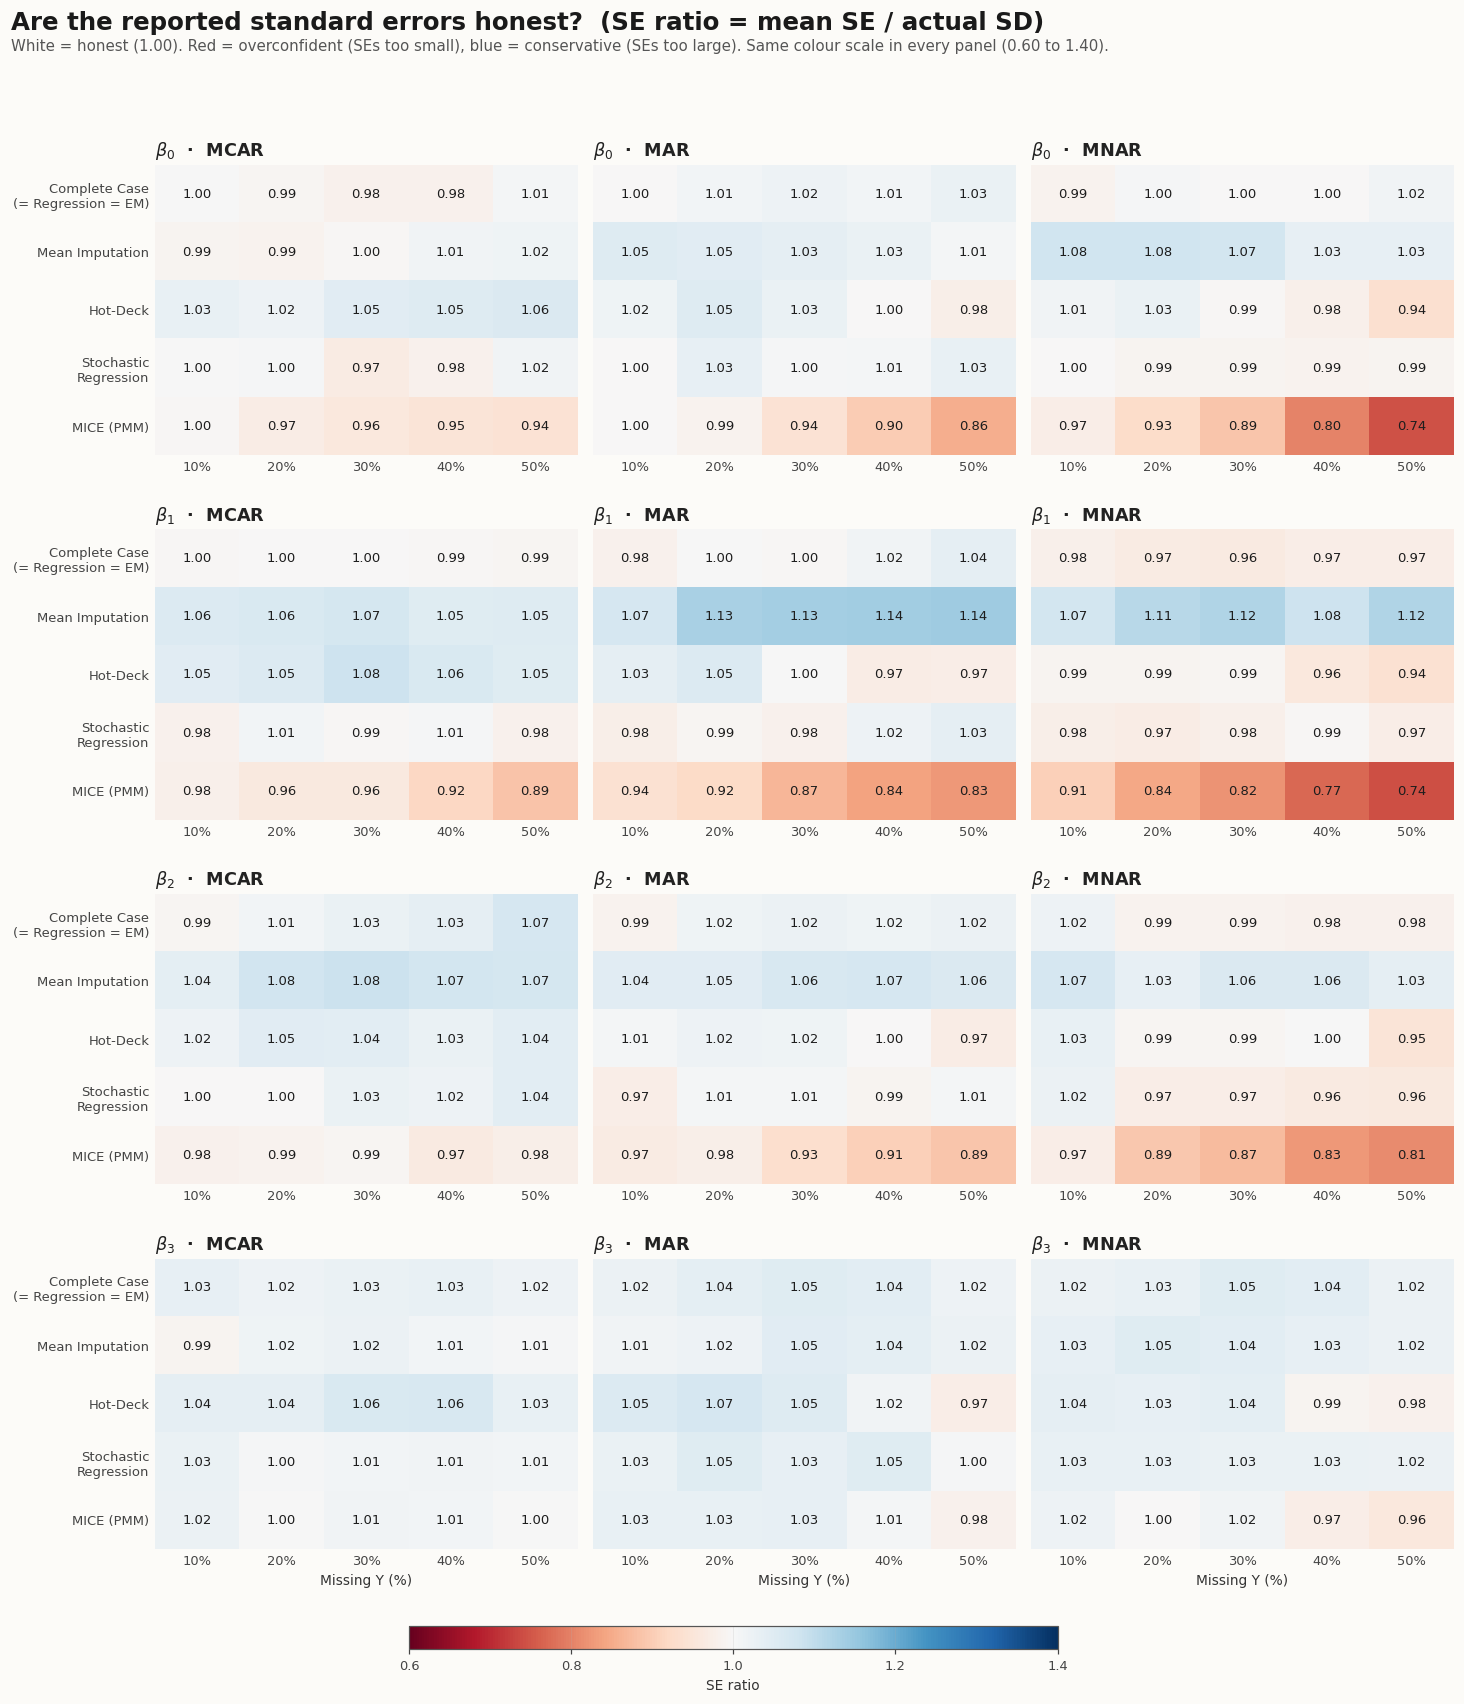

'part2B_outputs/figures/fig17_se_ratio_heatmaps.png'

In [18]:
# 6.2  SE-ratio heatmaps (all coefficients x mechanisms)
heat_grid("se_ratio", "Are the reported standard errors honest?  (SE ratio = mean SE / actual SD)",
          "White = honest (1.00). Red = overconfident (SEs too small), blue = conservative (SEs too large). Same colour scale in every panel (0.60 to 1.40).",
          "RdBu", TwoSlopeNorm(vcenter=1.0, vmin=0.6, vmax=1.4), "{:.2f}", "fig17_se_ratio_heatmaps", cbar_label="SE ratio", ticks=[0.6, 0.8, 1.0, 1.2, 1.4])

In [19]:
# 6.3  Bias-versus-SE decomposition from the z-scores
from scipy.stats import norm as _N
mu, sg = perf["mean_z"].to_numpy(), perf["sd_z"].to_numpy()
perf["cov_implied"] = _N.cdf((1.96 - mu) / sg) - _N.cdf((-1.96 - mu) / sg)         # normal-approx coverage, with the bias
perf["cov_if_no_bias"] = _N.cdf(1.96 / sg) - _N.cdf(-1.96 / sg)                    # same, bias removed: the SE's own contribution
perf["lost_to_bias"] = perf["cov_if_no_bias"] - perf["cov_implied"]
perf["lost_to_se"] = 0.95 - perf["cov_if_no_bias"]
save_table(perf, "performance_all_coefficients_with_decomposition", index=False)
sel = perf[perf["method"] != "Mean Imputation"]
gap = float(np.abs(sel["cov_implied"] - sel["coverage"]).mean())
record("6", "Normal-approximation coverage from the z-scores matches the observed coverage (mean abs gap < 0.04, excluding Mean Imputation)", gap < 0.04, f"mean abs gap {100 * gap:.1f} points")

def decomp_table(level):
    t = perf[perf["severity"] == level]
    g = t.groupby(["mechanism", "method"])[["coverage", "lost_to_bias", "lost_to_se"]].mean().reindex(pd.MultiIndex.from_product([MECHS, FAMS]))
    g.index = pd.MultiIndex.from_tuples([(a, FLAB1[b]) for a, b in g.index], names=["mechanism", "method"])
    return (100 * g).round(1).rename(columns={"coverage": "coverage (%)", "lost_to_bias": "lost to BIAS (pts)", "lost_to_se": "lost to SE (pts)"})
for lv in (30, 50):
    d_ = save_table(decomp_table(lv), f"coverage_decomposition_at_{lv}pct")
    display(Markdown(f"#### Where the coverage goes at {lv}% missingness (average over the four coefficients; negative 'lost to SE' = conservative SE)")); display(d_)

# honest-SE share: in what fraction of coefficient x level cells is each method's SE ratio within the honest band?
perf["se_honest"] = perf["se_ratio"].between(*HONEST)
hs = perf[perf["method"] != "Mean Imputation"].groupby(["mechanism", "method"])["se_honest"].mean().unstack(0)[MECHS].reindex([f for f in FAMS if f != "Mean Imputation"])
hs.index = [FLAB1[f] for f in hs.index]
display(Markdown(f"#### Share of (coefficient × severity) cells with an honest SE ratio ({HONEST[0]:.2f}–{HONEST[1]:.2f})")); display((100 * hs).round(0))
save_table((100 * hs).round(0), "se_honest_share")

PASS  [6] Normal-approximation coverage from the z-scores matches the observed coverage (mean abs gap < 0.04, excluding Mean Imputation)  ->  mean abs gap 1.9 points


#### Where the coverage goes at 30% missingness (average over the four coefficients; negative 'lost to SE' = conservative SE)

coverage (%)  lost to BIAS (pts)  \
mechanism method                                                                
MCAR      Complete Case (= Regression = EM)          93.4                 0.0   
          Mean Imputation                            43.2                50.5   
          Hot-Deck                                   91.9                 2.0   
          Stochastic Regression                      95.2                 0.0   
          MICE (PMM)                                 93.5                 0.9   
MAR       Complete Case (= Regression = EM)          93.9                 0.0   
          Mean Imputation                            24.9                68.8   
          Hot-Deck                                   82.6                 8.6   
          Stochastic Regression                      95.6                 0.0   
          MICE (PMM)                                 88.8                 5.0   
MNAR      Complete Case (= Regression = EM)          89.0                 4.3   
          Mean Imputation                             6.4                86.9   
          Hot-Deck                                   61.3                25.0   
          Stochastic Regression                      91.9                 3.6   
          MICE (PMM)                                 67.3                25.9   

                                             lost to SE (pts)  
mechanism method                                               
MCAR      Complete Case (= Regression = EM)               0.7  
          Mean Imputation                                -1.2  
          Hot-Deck                                       -0.6  
          Stochastic Regression                           0.8  
          MICE (PMM)                                      0.9  
MAR       Complete Case (= Regression = EM)               0.4  
          Mean Imputation                                -0.6  
          Hot-Deck                                        0.2  
          Stochastic Regression                           0.6  
          MICE (PMM)                                      2.3  
MNAR      Complete Case (= Regression = EM)               1.1  
          Mean Imputation                                 0.6  
          Hot-Deck                                        0.7  
          Stochastic Regression                           1.0  
          MICE (PMM)                                      3.4

#### Where the coverage goes at 50% missingness (average over the four coefficients; negative 'lost to SE' = conservative SE)

coverage (%)  lost to BIAS (pts)  \
mechanism method                                                                
MCAR      Complete Case (= Regression = EM)          93.0                 0.0   
          Mean Imputation                            27.2                61.6   
          Hot-Deck                                   86.4                 5.3   
          Stochastic Regression                      95.2                 0.0   
          MICE (PMM)                                 90.0                 3.8   
MAR       Complete Case (= Regression = EM)          93.0                 0.0   
          Mean Imputation                             5.8                79.0   
          Hot-Deck                                   64.6                20.3   
          Stochastic Regression                      95.0                 0.0   
          MICE (PMM)                                 75.4                17.4   
MNAR      Complete Case (= Regression = EM)          83.5                10.0   
          Mean Imputation                             0.4                78.3   
          Hot-Deck                                   31.8                48.5   
          Stochastic Regression                      86.9                 8.4   
          MICE (PMM)                                 32.1                55.1   

                                             lost to SE (pts)  
mechanism method                                               
MCAR      Complete Case (= Regression = EM)               0.9  
          Mean Imputation                                 4.6  
          Hot-Deck                                       -0.2  
          Stochastic Regression                           0.9  
          MICE (PMM)                                      2.3  
MAR       Complete Case (= Regression = EM)               0.6  
          Mean Imputation                                 9.1  
          Hot-Deck                                        3.1  
          Stochastic Regression                           0.5  
          MICE (PMM)                                      4.9  
MNAR      Complete Case (= Regression = EM)               1.5  
          Mean Imputation                                15.8  
          Hot-Deck                                        4.8  
          Stochastic Regression                           1.5  
          MICE (PMM)                                      9.1

#### Share of (coefficient × severity) cells with an honest SE ratio (0.90–1.10)

mechanism,MCAR,MAR,MNAR
Complete Case (= Regression = EM),100.0,100.0,100.0
Hot-Deck,100.0,100.0,100.0
Stochastic Regression,100.0,100.0,100.0
MICE (PMM),95.0,70.0,45.0


mechanism,MCAR,MAR,MNAR
Complete Case (= Regression = EM),100.0,100.0,100.0
Hot-Deck,100.0,100.0,100.0
Stochastic Regression,100.0,100.0,100.0
MICE (PMM),95.0,70.0,45.0


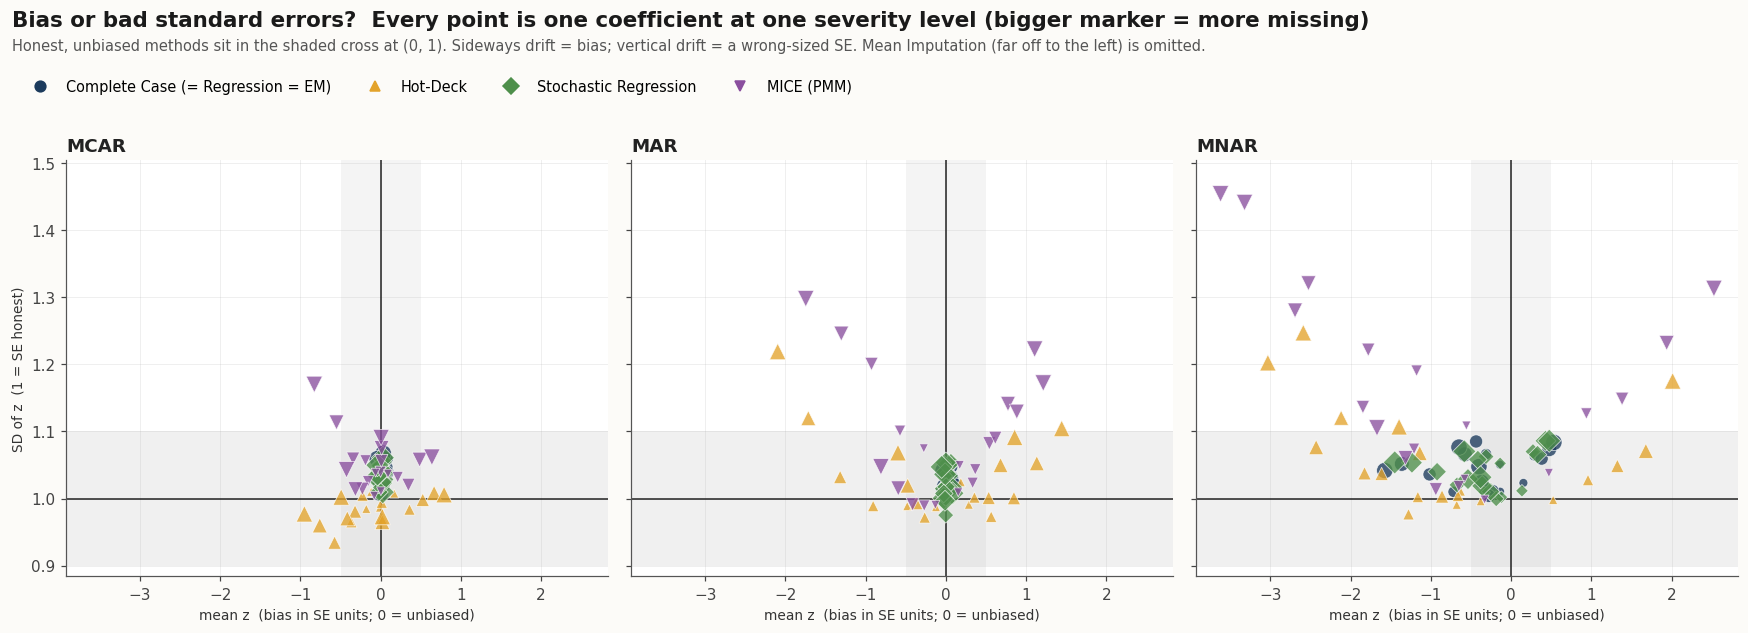

'part2B_outputs/figures/fig18_bias_vs_se_calibration.png'

In [20]:
# 6.4  Figure: mean z (bias in SE units) vs SD z (SE calibration)
def z_figure():
    _q = perf[perf["method"] != "Mean Imputation"]
    XL = (min(-1.0, _q["mean_z"].min() - 0.3), max(1.0, _q["mean_z"].max() + 0.3)); YL = (min(0.9, _q["sd_z"].min() - 0.05), max(1.2, _q["sd_z"].max() + 0.05))
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), facecolor=FIG_BG, sharey=True)
    for mi, mech in enumerate(MECHS):
        ax = axes[mi]
        ax.axhspan(0.9, 1.1, color="#999999", alpha=0.14, lw=0); ax.axvspan(-0.5, 0.5, color="#999999", alpha=0.10, lw=0)
        ax.axhline(1, color="#222", lw=1); ax.axvline(0, color="#222", lw=1)
        for f in FAMS:
            if f == "Mean Imputation": continue
            t = perf[(perf["mechanism"] == mech) & (perf["method"] == f)]
            ax.scatter(t["mean_z"], t["sd_z"], s=14 + 2.0 * t["severity"], color=PAL[f], marker=MARK[f], alpha=0.78, edgecolor="white", linewidth=0.5, zorder=3)
        ax.set_xlim(XL); ax.set_ylim(YL); ax.set_facecolor("white")
        ax.set_title(mech, loc="left", fontsize=12, fontweight="bold", color="#222222")
        ax.set_xlabel("mean z  (bias in SE units; 0 = unbiased)", fontsize=9)
        if mi == 0: ax.set_ylabel("SD of z  (1 = SE honest)", fontsize=9)
    h = [Line2D([0], [0], marker=MARK[f], color=PAL[f], lw=0, ms=7, label=FLAB1[f]) for f in FAMS if f != "Mean Imputation"]
    fig.legend(handles=h, loc="upper left", bbox_to_anchor=(0.01, 0.93), ncol=4, frameon=False, fontsize=9.5)
    fig.suptitle("Bias or bad standard errors?  Every point is one coefficient at one severity level (bigger marker = more missing)", x=0.01, y=1.02, ha="left", fontsize=14, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.955, "Honest, unbiased methods sit in the shaded cross at (0, 1). Sideways drift = bias; vertical drift = a wrong-sized SE. Mean Imputation (far off to the left) is omitted.", fontsize=9.6, color="#555555")
    fig.tight_layout(rect=[0, 0, 1, 0.9], w_pad=1.2)
    return savefig(fig, "fig18_bias_vs_se_calibration")
z_figure()

---
## Section 7 · A diagnostic: why do the donor-based methods lose?

### 7.1 The pattern to explain
Hot-Deck and MICE (PMM) both fill each missing $Y$ with a value **borrowed from a donor row**. In Section 3 they fall behind Complete Case and Stochastic Regression even under MCAR and MAR, where all of them should be valid. One signature to look for: **attenuation**, meaning the slopes are pulled toward zero. For each replicate we compute the **average shrink factor of the three slopes**, $\tfrac13\sum_{j=1}^{3}\hat\beta_j/\beta_j$. A value of 1 means no distortion; 0.85 means slopes are on average 15% too small.

**Hypothesis (not tested in this notebook).** A row with an extreme predicted value (very high or low) has few similar donors, so its donors come from nearer the middle of the data; the imputed $Y$ is then pulled toward the centre, flattening the fitted plane. The more rows are missing, the fewer donors there are, and the stronger this should be. Descriptively, this predicts (a) shrink factors below 1 that **fall with the missingness level**, (b) **similar shrinkage across the three slopes**, and (c) none for methods that do not borrow donors. The figure checks (a)–(c); it cannot prove the cause. A direct test (varying the number of donors $k$, or the number of imputations) would need a new simulation and is outside this study.

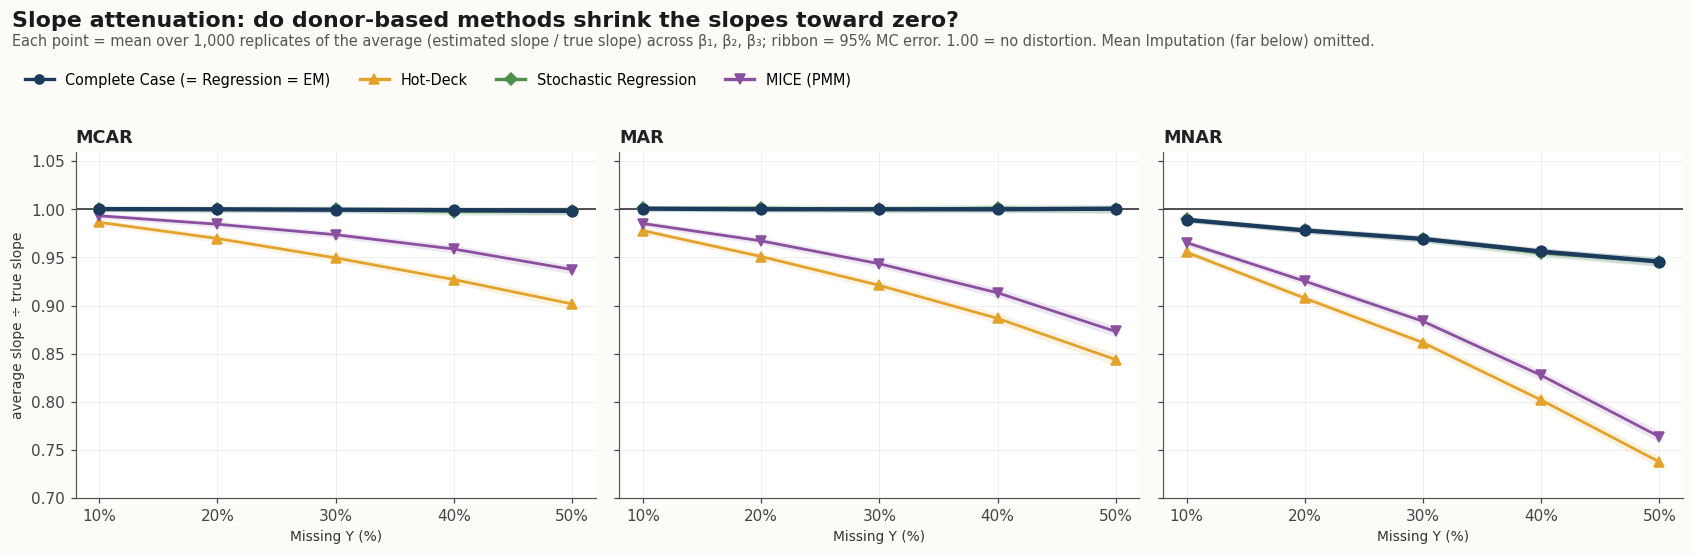

#### Shrink factor of each slope at 50% missingness (1.00 = no distortion)

shrink_b1               shrink_b2         \
mechanism                               MAR   MCAR   MNAR       MAR   MCAR   
Complete Case (= Regression = EM)     1.008  1.002  0.949     0.999  0.999   
Hot-Deck                              0.771  0.905  0.740     0.883  0.897   
Stochastic Regression                 1.007  1.002  0.950     1.001  0.999   
MICE (PMM)                            0.865  0.939  0.767     0.878  0.937   

                                         shrink_b3                
mechanism                           MNAR       MAR   MCAR   MNAR  
Complete Case (= Regression = EM)  0.947     0.995  0.994  0.942  
Hot-Deck                           0.738     0.878  0.903  0.735  
Stochastic Regression              0.947     0.992  0.994  0.939  
MICE (PMM)                         0.763     0.877  0.936  0.761

shrink_b1               shrink_b2         \
mechanism                               MAR   MCAR   MNAR       MAR   MCAR   
Complete Case (= Regression = EM)     1.008  1.002  0.949     0.999  0.999   
Hot-Deck                              0.771  0.905  0.740     0.883  0.897   
Stochastic Regression                 1.007  1.002  0.950     1.001  0.999   
MICE (PMM)                            0.865  0.939  0.767     0.878  0.937   

                                         shrink_b3                
mechanism                           MNAR       MAR   MCAR   MNAR  
Complete Case (= Regression = EM)  0.947     0.995  0.994  0.942  
Hot-Deck                           0.738     0.878  0.903  0.735  
Stochastic Regression              0.947     0.992  0.994  0.939  
MICE (PMM)                         0.763     0.877  0.936  0.761

In [21]:
# 7.2  Slope shrink factor by method, mechanism and severity
slopes = ["b1", "b2", "b3"]
shr = np.mean([EST[c] / TRUE[c] for c in slopes], axis=0)                      # (R, M, S, F): average shrink of the three slopes
shr_m, shr_se = shr.mean(0), shr.std(0, ddof=1) / np.sqrt(R)
shr_rows = [{"mechanism": MECHS[mi], "severity": s, "method": f, "shrink": shr_m[mi, si, fi], "mc_se": shr_se[mi, si, fi]}
            for mi in range(M_) for si, s in enumerate(LEVELS) for fi, f in enumerate(FAMS)]
shrink = pd.DataFrame(shr_rows)
for c in slopes:
    shrink[f"shrink_{c}"] = [1 + MA[c]["bias"][MECHS.index(r.mechanism), LEVELS.index(r.severity), FAMS.index(r.method)] / TRUE[c] for r in shrink.itertuples()]
save_table(shrink, "slope_shrink_factor", index=False)

def shrink_figure():
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.9), facecolor=FIG_BG, sharey=True)
    for mi, mech in enumerate(MECHS):
        ax = axes[mi]
        for f in FAMS:
            if f == "Mean Imputation": continue
            t = shrink[(shrink["mechanism"] == mech) & (shrink["method"] == f)].sort_values("severity")
            main = f == "Complete Case"
            ax.plot(t["severity"], t["shrink"], color=PAL[f], marker=MARK[f], ms=7 if main else 6, lw=2.8 if main else 1.8, zorder=4 if main else 3)
            ax.fill_between(t["severity"], t["shrink"] - 1.96 * t["mc_se"], t["shrink"] + 1.96 * t["mc_se"], color=PAL[f], alpha=0.14, lw=0)
        ax.axhline(1, color="#222", lw=1); ax.set_ylim(0.70, 1.06)
        style_ax(ax, mech, None, "average slope ÷ true slope" if mi == 0 else None)
    h = [Line2D([0], [0], color=PAL[f], marker=MARK[f], lw=2.2, ms=6, label=FLAB1[f]) for f in FAMS if f != "Mean Imputation"]
    fig.legend(handles=h, loc="upper left", bbox_to_anchor=(0.01, 0.93), ncol=4, frameon=False, fontsize=9.5)
    fig.suptitle("Slope attenuation: do donor-based methods shrink the slopes toward zero?", x=0.01, y=1.02, ha="left", fontsize=14.5, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.955, "Each point = mean over 1,000 replicates of the average (estimated slope / true slope) across β₁, β₂, β₃; ribbon = 95% MC error. 1.00 = no distortion. Mean Imputation (far below) omitted.",
             fontsize=9.5, color="#555555")
    fig.tight_layout(rect=[0, 0, 1, 0.9], w_pad=1.2)
    return savefig(fig, "fig19_slope_attenuation")
shrink_figure()
t50 = shrink[(shrink["severity"] == 50) & (shrink["method"] != "Mean Imputation")].copy()
tt = t50.pivot_table(index="method", columns="mechanism", values=["shrink_b1", "shrink_b2", "shrink_b3"]).reindex(FAMS[:1] + FAMS[2:])
tt.index = [FLAB1[f] for f in tt.index]
display(Markdown("#### Shrink factor of each slope at 50% missingness (1.00 = no distortion)")); display(tt.round(3)); save_table(tt.round(3), "slope_shrink_at_50pct")

---
## Section 8 · Findings and the "which method when" guide

### 8.1 How the guide is built (rules fixed in advance)
For every **mechanism × severity level × method**, a method gets a traffic light based on the **worst case over the four coefficients**:

| Light | Rule |
|---|---|
| 🟢 **Acceptable** | coverage ≥ 90% for **all four** coefficients **and** standardised bias < 0.5 SD for **all four** |
| 🟡 **Marginal** | passes exactly one of the two tests |
| 🔴 **Fails** | passes neither |

Among the 🟢 methods, the **recommended** one has the smallest worst-coefficient RMSE ratio. The **"mechanism unknown"** rows ask for a method that is 🟢 under **all three** mechanisms at that level, which is the realistic situation, because MAR versus MNAR cannot be tested from the observed data. If no method is 🟢, the guide says so rather than naming a "least bad" method as if it were fine.

#### The decision guide

,scenario,missing Y (%),recommended,also acceptable,fails (avoid),note
0,MCAR,10,Complete Case (= Regression = EM),"MICE (PMM), Stochastic Regression, Hot-Deck",Mean Imputation,
1,MCAR,20,Complete Case (= Regression = EM),"MICE (PMM), Stochastic Regression",Mean Imputation,
2,MCAR,30,Complete Case (= Regression = EM),"MICE (PMM), Stochastic Regression","Mean Imputation, Hot-Deck",
3,MCAR,40,Complete Case (= Regression = EM),Stochastic Regression,"Mean Imputation, Hot-Deck",
4,MCAR,50,Complete Case (= Regression = EM),Stochastic Regression,"Mean Imputation, Hot-Deck, MICE (PMM)",
5,MAR,10,Complete Case (= Regression = EM),"Stochastic Regression, MICE (PMM)","Mean Imputation, Hot-Deck",
6,MAR,20,Complete Case (= Regression = EM),Stochastic Regression,"Mean Imputation, Hot-Deck, MICE (PMM)",
7,MAR,30,Complete Case (= Regression = EM),Stochastic Regression,"Mean Imputation, Hot-Deck, MICE (PMM)",
8,MAR,40,Complete Case (= Regression = EM),Stochastic Regression,"Mean Imputation, Hot-Deck, MICE (PMM)",
9,MAR,50,Complete Case (= Regression = EM),Stochastic Regression,"Mean Imputation, Hot-Deck, MICE (PMM)",


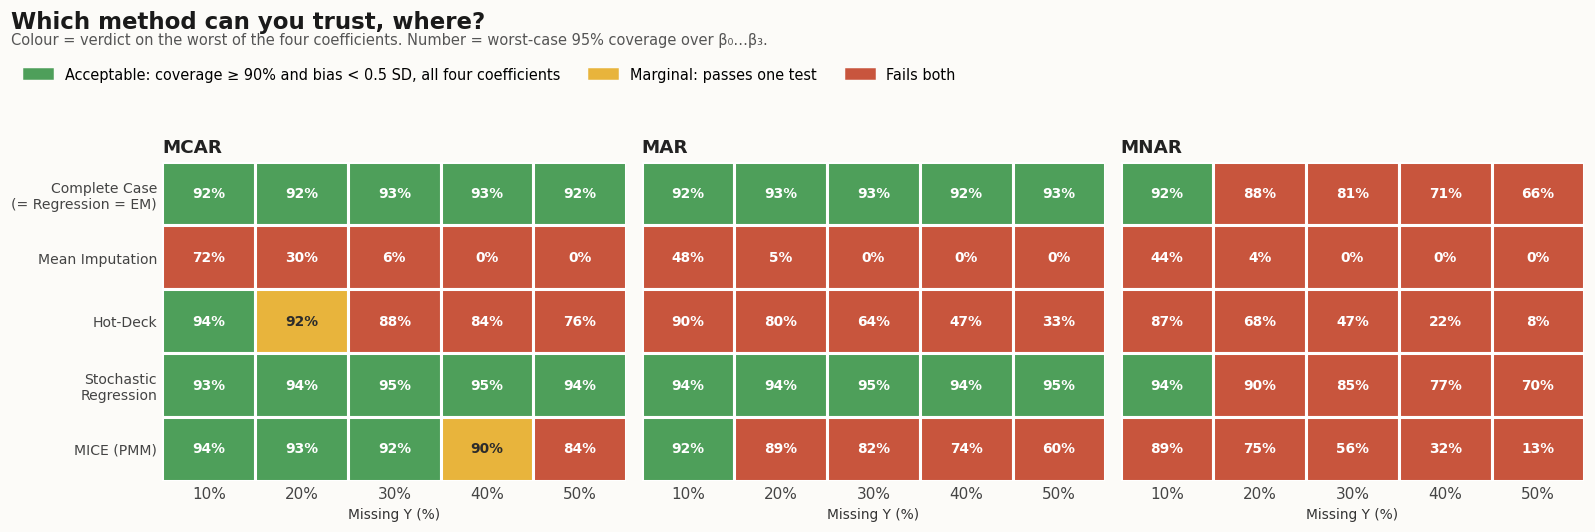

'part2B_outputs/figures/fig20_traffic_lights.png'

In [22]:
# 8.2  Traffic lights and the decision guide
def lights():
    st = {}
    for mi, m in enumerate(MECHS):
        for si, s in enumerate(LEVELS):
            for fi, f in enumerate(FAMS):
                ok_cov = wc[mi, si, fi] >= COVER_FLOOR
                ok_bias = wsb[mi, si, fi] < STD_BIAS_MATERIAL
                st[(m, s, f)] = "green" if (ok_cov and ok_bias) else ("amber" if (ok_cov or ok_bias) else "red")
    return st
ST = lights()
status = pd.DataFrame([{"mechanism": m, "severity": s, "method": f, "light": ST[(m, s, f)], "worst_coverage": wc[MECHS.index(m), LEVELS.index(s), FAMS.index(f)],
                        "worst_std_bias": wsb[MECHS.index(m), LEVELS.index(s), FAMS.index(f)], "worst_rmse_ratio": wr[MECHS.index(m), LEVELS.index(s), FAMS.index(f)]}
                       for (m, s, f) in ST])
save_table(status, "traffic_lights", index=False)

def pick(scen, s):
    """Return (recommended, also acceptable, avoid, note) for a scenario ('MCAR'/'MAR'/'MNAR'/'unknown') at level s."""
    mechs = MECHS if scen == "unknown" else [scen]
    green = [f for f in FAMS if all(ST[(m, s, f)] == "green" for m in mechs)]
    red = [f for f in FAMS if all(ST[(m, s, f)] == "red" for m in mechs) or any(ST[(m, s, f)] == "red" for m in mechs)]
    score = lambda f: max(wr[MECHS.index(m), LEVELS.index(s), FAMS.index(f)] for m in mechs)
    green = sorted(green, key=score)
    if green:
        return FLAB1[green[0]], ", ".join(FLAB1[g] for g in green[1:]) or "-", ", ".join(FLAB1[r] for r in red) or "-", ""
    best = min(FAMS, key=lambda f: (-min(wc[MECHS.index(m), LEVELS.index(s), FAMS.index(f)] for m in mechs), score(f)))
    cv = min(wc[MECHS.index(m), LEVELS.index(s), FAMS.index(best)] for m in mechs)
    return "NONE acceptable", "-", ", ".join(FLAB1[r] for r in red) or "-", f"best available: {FLAB1[best]} (worst coverage {100 * cv:.0f}%) - use a sensitivity analysis / MNAR model"
guide_rows = []
for scen in ["MCAR", "MAR", "MNAR", "unknown"]:
    for s in LEVELS:
        rec, also, avoid, note = pick(scen, s)
        guide_rows.append({"scenario": scen if scen != "unknown" else "mechanism unknown (any of the three)", "missing Y (%)": s,
                           "recommended": rec, "also acceptable": also, "fails (avoid)": avoid, "note": note})
guide = pd.DataFrame(guide_rows)
save_table(guide, "decision_guide", index=False)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(Markdown("#### The decision guide"))
display(guide)

# traffic-light figure
def light_figure():
    colr = {"green": "#4E9F5A", "amber": "#E8B43C", "red": "#C8553D"}
    fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.7), facecolor=FIG_BG)
    for mi, m in enumerate(MECHS):
        ax = axes[mi]
        for fi, f in enumerate(FAMS):
            for si, s in enumerate(LEVELS):
                ax.add_patch(plt.Rectangle((si - 0.5, fi - 0.5), 1, 1, color=colr[ST[(m, s, f)]], ec="white", lw=2))
                ax.text(si, fi, f"{100 * wc[mi, si, fi]:.0f}%", ha="center", va="center", fontsize=9, color=("#2b2b2b" if ST[(m, s, f)] == "amber" else "white"), fontweight="bold")
        ax.set_xlim(-0.5, 4.5); ax.set_ylim(len(FAMS) - 0.5, -0.5); ax.set_xticks(range(5)); ax.set_xticklabels([f"{s}%" for s in LEVELS])
        ax.set_yticks(range(len(FAMS))); ax.set_yticklabels([FLAB[f] for f in FAMS] if mi == 0 else [], fontsize=9.2); ax.set_ylim(len(FAMS) - 0.5, -0.5)
        ax.grid(False); ax.set_title(m, loc="left", fontsize=12, fontweight="bold", color="#222222"); ax.set_xlabel("Missing Y (%)", fontsize=9)
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.tick_params(length=0)
    h = [plt.Rectangle((0, 0), 1, 1, color=colr[k]) for k in ("green", "amber", "red")]
    fig.legend(h, ["Acceptable: coverage ≥ 90% and bias < 0.5 SD, all four coefficients", "Marginal: passes one test", "Fails both"], loc="upper left", bbox_to_anchor=(0.01, 0.935), ncol=3, frameon=False, fontsize=9.5)
    fig.suptitle("Which method can you trust, where?", x=0.01, y=1.02, ha="left", fontsize=15, fontweight="bold", color="#1a1a1a")
    fig.text(0.01, 0.955, "Colour = verdict on the worst of the four coefficients. Number = worst-case 95% coverage over β₀…β₃.", fontsize=9.6, color="#555555")
    fig.tight_layout(rect=[0, 0, 1, 0.88], w_pad=1.0)
    return savefig(fig, "fig20_traffic_lights")
light_figure()

### 8.3 Findings
Every number below is checked against the data in cell 8.4. If you re-run with the same input, all claim checks pass. *"Worst case"* always means the weakest of the four coefficients.

**1. Under MCAR and MAR, Complete Case is the method to beat, and nothing beats it.**
Its coverage stays at 92–95% for all four coefficients up to 50% missingness, and MAR makes **no detectable difference** relative to MCAR on the same datasets (paired |z| < 2.5 for bias and < 3 for coverage, at every level and coefficient). Its worst-coefficient RMSE ratio grows from 1.06 to 1.48 (MCAR) and from 1.12 to 1.73 (MAR) between 10% and 50%, which is the unavoidable cost of losing half the outcomes. Stochastic Regression matches its coverage and bias but is 6–11% less accurate (1.64 vs 1.48 at 50% MCAR). In the within-coefficient ranking at 50%, the order is the same for every coefficient and every mechanism: **Complete Case > Stochastic Regression > MICE > Hot-Deck > Mean Imputation**. This is what theory predicts for this design (only $Y$ is incomplete and $X$ is fully observed, so there is nothing for an imputation model to add), and it should not be read as "imputation never helps" (see the limits in 8.5).

**2. MNAR hurts through the intercept first.**
Complete Case coverage of **β₀** falls 92% → 88% → 81% → 71% → 66% from 10% to 50% missing, with bias growing to −0.25 (about 2.5 Full-Data SDs). The slopes hold up much better (β₁ never below 87%, β₂ 90%, β₃ 91%), so an analysis of β₁ alone would have called Complete Case "mildly affected" and missed the main effect. The cause is **bias, not bad SEs**: at 50% the SE ratio is 1.02 (honest), and of the ≈30 points of β₀ coverage lost, ≈30 are lost to bias and ≈1 to the SE. Complete Case breaks (coverage < 90%) at about **16%** missing and its bias becomes material at about **13%**. **No method is acceptable under MNAR beyond 10%**; Stochastic Regression is a close second to Complete Case, and Hot-Deck, MICE and Mean Imputation are worse.

**3. Two methods that are valid under MAR are hurt by MAR much more than Complete Case.**
At 50% missing under MAR, β₁ coverage is 93% (Complete Case), 95% (Stochastic Regression), **60% (MICE)** and **33% (Hot-Deck)**. Compared with MCAR on the same datasets, the change is +0.9 points for Complete Case but **−23.5 for MICE and −43.6 for Hot-Deck** (the method × mechanism interaction of Section 5). Both also lose under MCAR at high levels (β₁ coverage 84% and 76% at 50%). The diagnostic in Section 7 shows why they lose in the *estimates*: both **attenuate the slopes**. At 50% missing the average slope is 0.94 / 0.87 / 0.76 of its true value for MICE under MCAR / MAR / MNAR (0.90 / 0.84 / 0.74 for Hot-Deck), against 1.00 for Complete Case and Stochastic Regression under MCAR and MAR, and the shrinkage deepens steadily with the missingness level. That is the pattern a "donors drawn from the middle of the data" explanation predicts; this notebook shows the pattern but **does not test the cause**.

**4. Standard errors: Hot-Deck's are honest, MICE's are not.**
Complete Case, Hot-Deck and Stochastic Regression have an SE ratio within 0.90–1.10 in **every** coefficient × severity cell under every mechanism, so Hot-Deck's failure is pure bias. MICE is honest in only 95% / 70% / 45% of cells (MCAR / MAR / MNAR), and at 50% MNAR its SE ratio is 0.74 for β₀ and β₁ (SD of z = 1.45): it is **biased and overconfident**, which is why its coverage is the lowest of the donor methods under MNAR.

**5. Mean Imputation is the worst method everywhere, and the intercept alone would have hidden it.**
Its β₁ coverage is 72% even at 10% MCAR and it breaks before 3% missing for every mechanism. Yet under MCAR the *intercept's* coverage is 94–95% at every level (the observed mean is an unbiased estimate of the mean), which is a good example of why all four coefficients must be examined.

**6. If you do not know the mechanism, which is the usual situation, there is little to choose.**
MAR and MNAR cannot be told apart from the observed data. Taking the worst case over all three, **only Complete Case and Stochastic Regression are acceptable, and only up to about 10% missing**. Beyond that, none of the methods here is acceptable. The honest recommendation is Complete Case plus an explicit MNAR sensitivity analysis, not a hope that a cleverer imputation will rescue it. (The decision guide above shows the same, scenario by scenario.)

**7. The paired design paid off.** The Monte Carlo SE of a mechanism-vs-MCAR difference is about half (median 0.53, down to 0.21) of what two independent runs would give, which is why differences of 1–2 coverage points here are interpretable at all.

In [23]:
# 8.4  Claim check: every statement in 8.3 is verified against the data
P = perf.set_index(["coef", "mechanism", "severity", "method"])
def cov_(c, m, s, f): return float(P.loc[(c, m, s, f), "coverage"])
CCn, SRn, MIn, HDn, MEn = "Complete Case", "Stochastic Regression", "MICE", "Hot-Deck", "Mean Imputation"

# --- claim 1
cc_all = [cov_(c, m, s, CCn) for c in COEFS for m in ("MCAR", "MAR") for s in LEVELS]
record("8.4", "Claim 1a: Complete Case coverage is 92-95% (rounded) for all four coefficients under MCAR and MAR at every level",
       round(100 * min(cc_all)) == 92 and round(100 * max(cc_all)) == 95, f"range {100 * min(cc_all):.1f}% - {100 * max(cc_all):.1f}%")
wcc = worst[worst["method"] == CCn].set_index(["mechanism", "severity"])["worst_rmse_ratio"]
record("8.4", "Claim 1b: Complete Case worst-coefficient RMSE ratio goes 1.06 -> 1.48 (MCAR) and 1.12 -> 1.73 (MAR), 10% -> 50%",
       abs(wcc[("MCAR", 10)] - 1.06) < 0.01 and abs(wcc[("MCAR", 50)] - 1.48) < 0.01 and abs(wcc[("MAR", 10)] - 1.12) < 0.01 and abs(wcc[("MAR", 50)] - 1.73) < 0.01,
       f"MCAR {wcc[('MCAR', 10)]:.2f}->{wcc[('MCAR', 50)]:.2f}, MAR {wcc[('MAR', 10)]:.2f}->{wcc[('MAR', 50)]:.2f}")
ratio_sr = np.array([worst.set_index(["mechanism", "severity", "method"]).loc[(m, s, SRn), "worst_rmse_ratio"] / worst.set_index(["mechanism", "severity", "method"]).loc[(m, s, CCn), "worst_rmse_ratio"]
                     for m in MECHS for s in LEVELS])
record("8.4", "Claim 1c: Stochastic Regression is 6-11% less accurate than Complete Case (worst-coefficient RMSE ratio), MCAR and MAR",
       all(1.0 < ratio_sr.reshape(3, 5)[mi].min() for mi in (0, 1)) and ratio_sr.reshape(3, 5)[:2].min() > 1.05 and ratio_sr.reshape(3, 5)[:2].max() < 1.12, f"ratio range {ratio_sr.reshape(3, 5)[:2].min():.2f} - {ratio_sr.reshape(3, 5)[:2].max():.2f}")
r50 = ranks[ranks["severity"] == 50].pivot_table(index=["coef", "mechanism"], columns="method", values="rank")
order_ok = bool(((r50[CCn] == 1) & (r50[SRn] == 2) & (r50[MIn] == 3) & (r50[HDn] == 4) & (r50[MEn] == 5)).all())
record("8.4", "Claim 1d: at 50% the within-coefficient order is CC > Stochastic Regression > MICE > Hot-Deck > Mean, for every coefficient and mechanism", order_ok)
wk = worst.pivot_table(index=["mechanism", "severity"], columns="method", values="rank_worst")
record("8.4", "Claim 1e: worst-coefficient rank: Complete Case is 1st and Mean Imputation 5th and Hot-Deck 4th at all 15 mechanism x level combinations",
       bool((wk[CCn] == 1).all() and (wk[MEn] == 5).all() and (wk[HDn] == 4).all()))

ccm = paired[(paired["method"] == CCn) & (paired["mechanism"] == "MAR")]
record("8.4", "Claim 1f: Complete Case MAR-vs-MCAR paired differences: |z| < 2.5 for bias and < 3 for coverage, every level and coefficient",
       bool((ccm["d_bias_z"].abs() < 2.5).all() and (ccm["d_cov_z"].abs() < 3).all()), f"max |z|: bias {ccm['d_bias_z'].abs().max():.2f}, coverage {ccm['d_cov_z'].abs().max():.2f}")

# --- claim 2
cv0 = [cov_("b0", "MNAR", s, CCn) for s in LEVELS]
record("8.4", "Claim 2a: Complete Case beta0 coverage under MNAR falls monotonically 92/88/81/71/66%", all(np.diff(cv0) < 0) and [round(100 * v) for v in cv0] == [92, 88, 81, 71, 66],
       " / ".join(f"{100 * v:.0f}" for v in cv0))
record("8.4", "Claim 2b: under MNAR Complete Case slopes stay at or above 87% (beta1), 90% (beta2), 91% (beta3)",
       min(cov_("b1", "MNAR", s, CCn) for s in LEVELS) >= 0.865 and min(cov_("b2", "MNAR", s, CCn) for s in LEVELS) >= 0.895 and min(cov_("b3", "MNAR", s, CCn) for s in LEVELS) >= 0.905)
b50 = float(P.loc[("b0", "MNAR", 50, CCn), "bias"]); sb50 = float(P.loc[("b0", "MNAR", 50, CCn), "std_bias"])
record("8.4", "Claim 2c: Complete Case beta0 bias at 50% MNAR is about -0.25 (about 2.5 Full-Data SDs)", -0.27 < b50 < -0.23 and 2.3 < abs(sb50) < 2.7, f"bias {b50:.3f} = {sb50:.2f} SD")
lb, ls_ = float(P.loc[("b0", "MNAR", 50, CCn), "lost_to_bias"]), float(P.loc[("b0", "MNAR", 50, CCn), "lost_to_se"])
record("8.4", "Claim 2d: of Complete Case's beta0 coverage loss at 50% MNAR, about 30 points are bias and about 1 is SE; SE ratio is 1.02",
       lb > 10 * abs(ls_) and 0.27 < lb < 0.33 and abs(float(P.loc[("b0", "MNAR", 50, CCn), "se_ratio"]) - 1.016) < 0.01, f"bias {100 * lb:.1f} pts, SE {100 * ls_:.1f} pts")
b_cc = bp[(bp["method"] == CCn) & (bp["mechanism"] == "MNAR") & (bp["coef"] == "b0")].set_index("criterion")
record("8.4", "Claim 2e: Complete Case beta0 under MNAR breaks (coverage < 90%) at about 16% and bias becomes material at about 13%",
       abs(b_cc.loc["coverage", "bp"] - 16) < 1.5 and abs(b_cc.loc["bias", "bp"] - 13) < 1.5, f"{b_cc.loc['coverage', 'bp']:.1f}% and {b_cc.loc['bias', 'bp']:.1f}%")

# --- claim 3
dd = paired.set_index(["coef", "mechanism", "severity", "method"])
d_cc, d_mi, d_hd = [100 * float(dd.loc[("b1", "MAR", 50, f), "d_cov"]) for f in (CCn, MIn, HDn)]
record("8.4", "Claim 3a: MAR vs MCAR at 50% changes beta1 coverage by +0.9 (Complete Case), -23.5 (MICE), -43.6 (Hot-Deck) points",
       abs(d_cc - 0.9) < 0.3 and abs(d_mi + 23.5) < 0.3 and abs(d_hd + 43.6) < 0.3, f"{d_cc:+.1f} / {d_mi:+.1f} / {d_hd:+.1f}")
record("8.4", "Claim 3b: beta1 coverage at 50% MAR is 93 / 95 / 60 / 33 % (Complete Case / Stochastic Regression / MICE / Hot-Deck)",
       [round(100 * cov_("b1", "MAR", 50, f)) for f in (CCn, SRn, MIn, HDn)] == [93, 95, 60, 33])
record("8.4", "Claim 3c: beta1 coverage at 50% MCAR is 84% (MICE) and 76% (Hot-Deck)", round(100 * cov_("b1", "MCAR", 50, MIn)) == 84 and round(100 * cov_("b1", "MCAR", 50, HDn)) == 76)
sh50 = shrink[shrink["severity"] == 50].set_index(["method", "mechanism"])["shrink"]
record("8.4", "Claim 3d: average slope / true slope at 50% = MICE 0.94/0.87/0.76 and Hot-Deck 0.90/0.84/0.74 (MCAR/MAR/MNAR); Complete Case and Stochastic Regression = 1.00 under MCAR, MAR",
       all(abs(sh50[(MIn, m)] - v) < 0.006 for m, v in zip(("MCAR", "MAR", "MNAR"), (0.937, 0.873, 0.764)))
       and all(abs(sh50[(HDn, m)] - v) < 0.006 for m, v in zip(("MCAR", "MAR", "MNAR"), (0.902, 0.844, 0.738)))
       and all(abs(sh50[(f, m)] - 1) < 0.006 for f in (CCn, SRn) for m in ("MCAR", "MAR")))
mono = all(np.all(np.diff(shrink[(shrink["method"] == f) & (shrink["mechanism"] == m)].sort_values("severity")["shrink"]) < 0) for f in (MIn, HDn) for m in MECHS)
record("8.4", "Claim 3e: MICE and Hot-Deck slope shrinkage deepens at every step from 10% to 50%, under every mechanism", bool(mono))

# --- claim 4
hs_ = perf[perf["method"].isin([CCn, HDn, SRn])]["se_ratio"]
record("8.4", "Claim 4a: Complete Case, Hot-Deck and Stochastic Regression have SE ratio within 0.90-1.10 in every coefficient x level x mechanism cell",
       bool(hs_.between(*HONEST).all()), f"range {hs_.min():.3f} - {hs_.max():.3f}")
hsm = perf[perf["method"] == MIn].groupby("mechanism")["se_honest"].mean()
record("8.4", "Claim 4b: MICE has an honest SE ratio in 95% / 70% / 45% of cells (MCAR / MAR / MNAR)",
       [round(100 * hsm[m]) for m in MECHS] == [95, 70, 45], " / ".join(f"{100 * hsm[m]:.0f}" for m in MECHS))
record("8.4", "Claim 4c: MICE at 50% MNAR: SE ratio about 0.74 for beta0 and beta1; SD of z = 1.45 (beta0)",
       abs(float(P.loc[("b0", "MNAR", 50, MIn), "se_ratio"]) - 0.745) < 0.01 and abs(float(P.loc[("b1", "MNAR", 50, MIn), "se_ratio"]) - 0.742) < 0.01
       and abs(float(P.loc[("b0", "MNAR", 50, MIn), "sd_z"]) - 1.454) < 0.01)

# --- claim 5
record("8.4", "Claim 5a: Mean Imputation beta1 coverage is 72% at 10% MCAR", round(100 * cov_("b1", "MCAR", 10, MEn)) == 72)
bpm = bp[(bp["method"] == MEn) & (bp["criterion"] == "coverage") & (bp["coef"] == "b1")].set_index("mechanism")["bp"]
record("8.4", "Claim 5b: Mean Imputation beta1 coverage breaks before 3% under every mechanism", bool((bpm < 3).all()), ", ".join(f"{m} {bpm[m]:.1f}%" for m in MECHS))
record("8.4", "Claim 5c: Mean Imputation beta0 coverage under MCAR is 94-95% at every level", all(0.935 <= cov_("b0", "MCAR", s, MEn) <= 0.955 for s in LEVELS))

# --- claim 6 (decision guide)
g_ = lambda m, s, f: ST[(m, s, f)]
record("8.4", "Claim 6a: under MNAR no method is acceptable at 20-50%, and only Complete Case and Stochastic Regression at 10%",
       all(g_("MNAR", s, f) != "green" for s in (20, 30, 40, 50) for f in FAMS) and [f for f in FAMS if g_("MNAR", 10, f) == "green"] == [CCn, SRn])
record("8.4", "Claim 6b: Complete Case and Stochastic Regression are acceptable at every level under MCAR and MAR",
       all(g_(m, s, f) == "green" for m in ("MCAR", "MAR") for s in LEVELS for f in (CCn, SRn)))
unk = {s: [f for f in FAMS if all(g_(m, s, f) == "green" for m in MECHS)] for s in LEVELS}
record("8.4", "Claim 6c: mechanism unknown: only Complete Case and Stochastic Regression at 10%, no method at 20-50%",
       unk[10] == [CCn, SRn] and all(unk[s] == [] for s in (20, 30, 40, 50)))

# --- claim 7
chk = paired.merge(perf[perf["mechanism"] == "MCAR"][["coef", "severity", "method", "mc_se_bias"]], on=["coef", "severity", "method"]) \
            .merge(perf[["coef", "mechanism", "severity", "method", "mc_se_bias"]], on=["coef", "mechanism", "severity", "method"], suffixes=("_mcar", "_mech"))
chk = chk[chk["method"] != MEn]
rr = chk["d_bias_se"] / np.sqrt(chk["mc_se_bias_mcar"] ** 2 + chk["mc_se_bias_mech"] ** 2)
record("8.4", "Claim 7: paired MC SE of the mechanism difference is about half the unpaired (median 0.53, minimum about 0.21)",
       abs(rr.median() - 0.53) < 0.03 and abs(rr.min() - 0.21) < 0.03, f"median {rr.median():.2f}, min {rr.min():.2f}")

PASS  [8.4] Claim 1a: Complete Case coverage is 92-95% (rounded) for all four coefficients under MCAR and MAR at every level  ->  range 91.6% - 94.6%
PASS  [8.4] Claim 1b: Complete Case worst-coefficient RMSE ratio goes 1.06 -> 1.48 (MCAR) and 1.12 -> 1.73 (MAR), 10% -> 50%  ->  MCAR 1.06->1.48, MAR 1.12->1.73
PASS  [8.4] Claim 1c: Stochastic Regression is 6-11% less accurate than Complete Case (worst-coefficient RMSE ratio), MCAR and MAR  ->  ratio range 1.06 - 1.11
PASS  [8.4] Claim 1d: at 50% the within-coefficient order is CC > Stochastic Regression > MICE > Hot-Deck > Mean, for every coefficient and mechanism
PASS  [8.4] Claim 1e: worst-coefficient rank: Complete Case is 1st and Mean Imputation 5th and Hot-Deck 4th at all 15 mechanism x level combinations
PASS  [8.4] Claim 1f: Complete Case MAR-vs-MCAR paired differences: |z| < 2.5 for bias and < 3 for coverage, every level and coefficient  ->  max |z|: bias 2.42, coverage 1.95
PASS  [8.4] Claim 2a: Complete Case beta0 coverage un

### 8.5 What these findings do NOT cover
The decision guide is a statement about **this** design, and several of its results depend on it:

* **Only $Y$ is incomplete; the predictors are always observed, and there are no auxiliary variables.** This is the setting in which Complete Case is theoretically valid under MAR and in which imputation has nothing extra to exploit. Complete Case "winning" here says nothing about settings where predictors are missing or where variables outside the model predict $Y$ or its missingness; there, multiple imputation can win decisively.
* **MICE here is a specific PMM implementation (k = 5 donors, m = 20).** Its slope attenuation may be partly a feature of that choice; other donor counts, imputation models or software could behave differently. The donor-depletion explanation in Section 7 is a hypothesis, not a result.
* **One MNAR strength (slope 1.0 on standardised $Y$).** The "10% under MNAR" threshold would move with a weaker or stronger mechanism. Part 1's weaker MNAR (slope 0.5) was not re-run in this study, so no statement is made about it.
* **MAR here is stronger than Part 1's rule** (standardised $X_1$ gap about 0.97 SD, against about 0.5 SD) and deletes an exact count.
* **One model, one sample size:** linear, normal errors, n = 100, three predictors.
* **The traffic lights use hard thresholds** (90% coverage, 0.5 SD bias). A method just above or below a line is a close call; the breaking-point intervals in Section 4 show how close.
* **Many comparisons.** Flags use $|z|>3$ and the paired SEs are Monte Carlo errors only, so they say nothing about model misspecification.

---
## Section 9 · Report card and export

### 9.1 Report card
Every check in this notebook in one table. **Section 1** (input validation) and the structural checks in Sections 2, 4 and 6 should all say PASS. A FAIL in **8.4** means a sentence in the written findings no longer matches the data, which would happen if the input file changed; treat it as "the text needs updating", not as a bug. A **SKIP** means an optional cross-check was not possible.

In [24]:
# 9.1  Report card
report = pd.DataFrame(TESTS)
report.to_csv(f"{OUT}/tables/report_card_part2B.csv", index=False)
pd.set_option("display.max_colwidth", 130, "display.width", 240, "display.max_rows", 200)
display(report)
n_pass, n_fail, n_skip = [int((report["result"] == k).sum()) for k in ("PASS", "FAIL", "SKIP")]
claims_fail = int(((report["result"] == "FAIL") & (report["section"] == "8.4")).sum())
struct_fail = n_fail - claims_fail
print(f"\n{n_pass} checks passed, {n_fail} failed, {n_skip} skipped.")
if n_fail == 0 and n_skip == 0:
    print("PART 2B STATUS: ALL CHECKS PASSED - every sentence in the findings is verified against the data")
elif struct_fail == 0 and claims_fail == 0:
    print("PART 2B STATUS: no failures; some optional cross-checks were skipped - see the table")
elif struct_fail == 0:
    print("PART 2B STATUS: analysis is sound, but some written findings no longer match the data (8.4) - the text needs updating")
else:
    print("PART 2B STATUS: A STRUCTURAL CHECK FAILED - do not use these results; send me the table")

,section,check,result,detail
0,1,"All required columns are present (estimates, SEs and intervals of all four coefficients)",PASS,
1,1,Row count = replicates x 106 (1 Full Data row + 3 mechanisms x 5 levels x 7 methods),PASS,"106,000 rows, 1000 replicates"
2,1,Every replicate appears exactly once in every condition,PASS,106 conditions x 1000
3,1,"No missing values in estimates, SEs or interval limits",PASS,
4,1,All four SEs and all interval widths are positive,PASS,
5,1,n_missing equals the severity level in every row (exact deletion),PASS,
6,1,"Design is as expected (mechanisms MCAR/MAR/MNAR, levels 10-50%, 7 methods + Full Data)",PASS,
7,1,"Complete Case = Regression Imputation = EM in every estimate, SE and interval (so they are merged below)",PASS,max difference 7.6e-08
8,1,Full Data: all four coefficients unbiased (|bias| < 4 Monte Carlo SE),PASS,largest z = 1.58
9,1,Full Data: 95% coverage within 3.5 Monte Carlo SE for every coefficient,PASS,95.7% / 94.1% / 95.3% / 94.7%



41 checks passed, 0 failed, 0 skipped.
PART 2B STATUS: ALL CHECKS PASSED - every sentence in the findings is verified against the data


### 9.2 Export: figures, tables, README snippet
Creates **`part2B_outputs.zip`** (downloads automatically):

| Folder / file | Contents |
|---|---|
| `figures/` | Figures 10–20 (PNG, 200 dpi) |
| `tables/` | every table shown above as CSV, including the full performance table, paired differences, rankings, breaking points, decision guide and the report card |
| `README_part2B_results.md` | a ready-to-paste **Results** section for the project README: headline findings (numbers filled in from the data), key tables in Markdown, the decision guide, figure links and limitations |
| `config_and_environment.json` | settings, thresholds, input description, software versions |

In [25]:
# 9.2  README snippet, config, zip
def md_table(df, index=True):
    d = df.reset_index() if index else df
    head = "| " + " | ".join(str(c) for c in d.columns) + " |"
    sep = "|" + "|".join("---" for _ in d.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in d.itertuples(index=False)]
    return "\n".join([head, sep] + body)
nm = lambda f: FLAB1[f]
cov50 = lambda c, m, f: 100 * float(P.loc[(c, m, 50, f), "coverage"])

# Table A: worst-case coverage by method x mechanism at 10 / 30 / 50
tA = worst[worst["severity"].isin([10, 30, 50])].copy()
tA["col"] = tA["mechanism"] + " " + tA["severity"].astype(str) + "%"
tA = tA.pivot(index="method", columns="col", values="worst_coverage").reindex(FAMS)[[f"{m} {s}%" for m in MECHS for s in (10, 30, 50)]]
tA = (100 * tA).round(0).astype(int).astype(str) + "%"; tA.index = [nm(f) for f in tA.index]; tA.index.name = "Worst-case coverage"
# Table B: weakest-link breaking points (coverage)
tB = wl_cov.copy(); tB.index.name = "Coverage < 90% at (% missing; weakest coefficient)"
# Table C: guide, one row per scenario, cell = recommended method (or NONE)
g2 = guide.copy(); g2["rec"] = g2["recommended"].str.replace(" (= Regression = EM)", "", regex=False).str.replace("NONE acceptable", "none")
tC = g2.pivot(index="scenario", columns="missing Y (%)", values="rec").reindex(["MCAR", "MAR", "MNAR", "mechanism unknown (any of the three)"])
tC.columns = [f"{c}%" for c in tC.columns]; tC.index.name = "Recommended method"
# Table D: coverage of the intercept vs slopes for Complete Case under MNAR
tD = (100 * perf[(perf["method"] == CCn) & (perf["mechanism"] == "MNAR")].pivot(index="coef", columns="severity", values="coverage")).round(0).astype(int).astype(str) + "%"
tD.index = [CNAME[c].replace("beta", "β") for c in tD.index]; tD.columns = [f"{c}%" for c in tD.columns]; tD.index.name = "Complete Case, MNAR: coverage"

snip = f"""## Part 2B: Comparison of methods and mechanisms

Part 2B compares the seven methods across the three mechanisms using the {R:,}-replicate severity simulation of Part 2A (n = 100, 10-50% of Y missing, B = 200 bootstrap resamples; MICE with Rubin's rules). All four coefficients (β₀…β₃) are treated equally; "worst case" means the weakest of the four. Complete Case, Regression Imputation and EM give identical results in this design and are shown as one method.

### Headline findings
* **MCAR and MAR: Complete Case is the method to beat.** Coverage is {100 * min(cc_all):.0f}-{100 * max(cc_all):.0f}% for every coefficient up to 50% missing, and MAR changes nothing relative to MCAR. Stochastic Regression matches its coverage with a {100 * (ratio_sr.reshape(3, 5)[:2].min() - 1):.0f}-{100 * (ratio_sr.reshape(3, 5)[:2].max() - 1):.0f}% larger RMSE.
* **MNAR hits the intercept first.** Complete Case coverage of β₀ falls from {100 * cv0[0]:.0f}% (10% missing) to {100 * cv0[-1]:.0f}% (50%), bias reaching {b50:.2f}; the slopes stay at or above 87%. Coverage breaks at about {b_cc.loc['coverage', 'bp']:.0f}% missing. The loss is bias, not standard errors (SE ratio about 1.0). No method is acceptable under MNAR beyond 10% missing.
* **MICE and Hot-Deck are hurt by MAR far more than Complete Case.** At 50% under MAR, β₁ coverage is {cov50('b1', 'MAR', 'Complete Case'):.0f}% (Complete Case), {cov50('b1', 'MAR', 'Stochastic Regression'):.0f}% (Stochastic Regression), {cov50('b1', 'MAR', 'MICE'):.0f}% (MICE), {cov50('b1', 'MAR', 'Hot-Deck'):.0f}% (Hot-Deck). Both attenuate the slopes (average slope / true slope at 50% under MAR: MICE {sh50[('MICE', 'MAR')]:.2f}, Hot-Deck {sh50[('Hot-Deck', 'MAR')]:.2f}; donor depletion is a hypothesis, not tested).
* **Standard errors:** Hot-Deck's are honest (its failure is pure bias); MICE is both biased and overconfident (honest in {100 * hsm['MCAR']:.0f}% / {100 * hsm['MAR']:.0f}% / {100 * hsm['MNAR']:.0f}% of cells under MCAR / MAR / MNAR).
* **Mean Imputation is the worst method everywhere**, although its intercept is fine under MCAR, which is why all four coefficients matter.
* **If the mechanism is unknown, only Complete Case and Stochastic Regression are acceptable, and only up to about 10% missing.** Beyond that, report Complete Case with an MNAR sensitivity analysis.

{md_table(tA)}

{md_table(tD)}

{md_table(tB)}

### Which method when
Acceptable = coverage >= 90% and |bias| < 0.5 SD of the Full-Data estimator, for all four coefficients. Recommended = the acceptable method with the smallest worst-coefficient RMSE ratio.

{md_table(tC)}

### Figures
| Figure | File |
|---|---|
| Paired change in bias vs MCAR | `figures/fig10_paired_change_in_bias.png` |
| Paired change in coverage vs MCAR | `figures/fig11_paired_change_in_coverage.png` |
| RMSE relative to Full Data | `figures/fig12_rmse_ratio_heatmaps.png` |
| Coverage heatmaps | `figures/fig13_coverage_heatmaps.png` |
| Breaking points | `figures/fig14_breaking_points.png` |
| Method x mechanism interaction | `figures/fig15_interaction_coverage.png` |
| Worst case over mechanisms | `figures/fig16_worst_case_over_mechanisms.png` |
| SE ratio heatmaps | `figures/fig17_se_ratio_heatmaps.png` |
| Bias vs SE calibration | `figures/fig18_bias_vs_se_calibration.png` |
| Slope attenuation | `figures/fig19_slope_attenuation.png` |
| Traffic lights (decision guide) | `figures/fig20_traffic_lights.png` |

### Limits of these conclusions
Only Y is incomplete and the predictors are always observed (no auxiliary variables), which is the setting where Complete Case is valid under MAR and imputation has nothing extra to use; one MNAR strength (slope 1.0); MAR is stronger than Part 1's rule; MICE is a PMM implementation with k = 5 donors and m = 20; one linear model with n = 100. The thresholds (coverage 90%, bias 0.5 SD) are conventions, and the breaking-point intervals show how close each call is.
"""
open(f"{OUT}/README_part2B_results.md", "w", encoding="utf-8").write(snip)

config = {"stage": "Part 2B - Comparison", "run_date": time.strftime("%Y-%m-%d %H:%M"),
          "input": {"source": raw_src, "rows": int(len(raw)), "replicates": R, "summary_cross_check": summ_src},
          "thresholds": {"COVER_FLOOR": COVER_FLOOR, "STD_BIAS_MATERIAL": STD_BIAS_MATERIAL, "REL_BIAS_REF": REL_BIAS_REF, "HONEST": HONEST, "Z_FLAG": Z_FLAG, "TIE_Z": TIE_Z},
          "bootstrap": {"N_BOOT": N_BOOT, "seed": BOOT_SEED}, "true_beta": TRUE, "sd_full_data_estimator": SD_FULL,
          "method_families": {"Complete Case": ["Complete Case", "Regression Imputation", "EM"]},
          "checks": {"passed": n_pass, "failed": n_fail, "skipped": n_skip},
          "environment": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}}
json.dump(config, open(f"{OUT}/config_and_environment.json", "w"), indent=2, default=str)

zip_base = "part2B_outputs"
shutil.make_archive(zip_base, "zip", ".", OUT)
print(f"Created {zip_base}.zip ({os.path.getsize(zip_base + '.zip') / 1e6:.1f} MB)")
if STORE != "local_store":
    shutil.copy(zip_base + ".zip", f"{STORE}/{zip_base}.zip"); print("Copy saved to Drive:", f"{STORE}/{zip_base}.zip")
for root, _, fs in os.walk(OUT):
    for fn in sorted(fs):
        p_ = os.path.join(root, fn); print(f"  {p_[len(OUT) + 1:]:<62s}{os.path.getsize(p_) / 1024:>9.1f} KB")
try:
    from google.colab import files
    files.download(zip_base + ".zip")
except Exception:
    print("\n(Not in Colab, or the download was blocked: the zip is in the working folder.)")

Created part2B_outputs.zip (4.3 MB)
Copy saved to Drive: /content/drive/MyDrive/MissingData_Part2A_Stage2_v2/part2B_outputs.zip
  README_part2B_results.md                                            4.8 KB
  config_and_environment.json                                         1.2 KB
  tables/breaking_point_coverage_below_90.csv                         1.0 KB
  tables/breaking_point_material_bias.csv                             1.0 KB
  tables/breaking_points.csv                                          8.4 KB
  tables/coverage_decomposition_at_30pct.csv                          0.6 KB
  tables/coverage_decomposition_at_50pct.csv                          0.6 KB
  tables/decision_guide.csv                                           3.2 KB
  tables/interaction_bias_at_50pct.csv                                0.6 KB
  tables/interaction_cov_at_50pct.csv                                 0.6 KB
  tables/interaction_did_vs_complete_case.csv                        25.8 KB
  tables/paired_differenc

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>